# Unit10 Ridge回歸 (v2) | 小樣本 + 高度多重共線性下的正則化優勢

本 Notebook 是 `Unit10_Ridge_Regression.ipynb` 的進階版本。

原範例使用 500 筆樣本、只有 4 個特徵，且特徵間相關係數僅約 0.6，結果 OLS 與 Ridge 的表現幾乎相同（測試集 $R^2$ 差距不到 0.01），**完全看不出 Ridge 的真正價值**。

本版本改以「**小樣本 + 高度共線性**」的工業反應器數據，讓 Ridge 的優勢具體可見、可量化。

## 目標
- 理解 Ridge 在樣本數與特徵數比值偏低（$n/p$ 小）、VIF 極高時的關鍵作用
- 觀察 OLS 係數在共線性下如何失控（符號翻轉、量級爆炸、無法物理解釋）
- 用 Bootstrap 量化係數估計的不穩定性
- 比較多次隨機切分與樣本數掃描下的泛化表現
- 掌握 RidgeCV 自動選擇正則化參數 $\alpha$ 的實務流程

## 案例背景
某反應器共有 **12 個量測訊號**，但真正的獨立操作變數只有 6 個：

| 訊號 | 說明 |
|------|------|
| T_TC1 / T_TC2 / T_TC3 | 3 支熱電偶量測**同一個**反應溫度 |
| P_PT1 / P_PT2 | 2 支壓力傳送器量測**同一個**壓力 |
| C_AT1 / C_AT2 | 2 支線上分析儀量測**同一個**催化劑濃度 |
| Coolant_C | 冷卻水溫度，與反應溫度**強負相關**（對產率無直接因果效應） |
| Residence_min | 滯留時間 |
| Stirring_rpm | 攪拌轉速 |
| Feed_rate | 進料速率 |
| Ambient_RH | 環境濕度（與產率無關） |

**挑戰**：僅有 50 筆批次紀錄，卻要估計 12 個係數，$n/p \approx 4$。

資料背景可參考：Unit10 線性模型系列講義

---
## 0. 環境設定

In [1]:
from pathlib import Path
import os

# ========================================
# 路徑設定 (兼容 Colab 與 Local)
# ========================================
UNIT_OUTPUT_DIR = 'P3_Unit10_Ridge_Regression_v2'

try:
    from google.colab import drive
    IN_COLAB = True
    print("✓ 偵測到 Colab 環境，準備掛載 Google Drive...")
    drive.mount('/content/drive', force_remount=True)
except ImportError:
    IN_COLAB = False
    print("✓ 偵測到 Local 環境")

try:
    shortcut_path = '/content/ChemE-3590'
    os.remove(shortcut_path)
except FileNotFoundError:
    pass

if IN_COLAB:
    source_path = Path('/content/drive/My Drive/Colab Notebooks/ChemE-3590')
    os.symlink(source_path, shortcut_path)
    shortcut_path = Path(shortcut_path)
    if source_path.exists():
        NOTEBOOK_DIR = shortcut_path / 'Part_3' / 'Unit10'
        OUTPUT_DIR = NOTEBOOK_DIR / 'outputs' / UNIT_OUTPUT_DIR
        MODEL_DIR = OUTPUT_DIR / 'models'
        FIG_DIR = OUTPUT_DIR / 'figs'
    else:
        print(f"⚠️ 找不到雲端ChemE-3590路徑，請確認自己的雲端資料夾是否正確")
else:
    NOTEBOOK_DIR = Path.cwd()
    OUTPUT_DIR = NOTEBOOK_DIR / 'outputs' / UNIT_OUTPUT_DIR
    MODEL_DIR = OUTPUT_DIR / 'models'
    FIG_DIR = OUTPUT_DIR / 'figs'

NOTEBOOK_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

print(f"\n✓ Notebook工作目錄: {NOTEBOOK_DIR}")
print(f"✓ 結果輸出目錄: {OUTPUT_DIR}")
print(f"✓ 模型輸出目錄: {MODEL_DIR}")
print(f"✓ 圖檔輸出目錄: {FIG_DIR}")

✓ 偵測到 Local 環境

✓ Notebook工作目錄: d:\MyGit\ChemE-3590\Part_3\Unit10
✓ 結果輸出目錄: d:\MyGit\ChemE-3590\Part_3\Unit10\outputs\P3_Unit10_Ridge_Regression_v2
✓ 模型輸出目錄: d:\MyGit\ChemE-3590\Part_3\Unit10\outputs\P3_Unit10_Ridge_Regression_v2\models
✓ 圖檔輸出目錄: d:\MyGit\ChemE-3590\Part_3\Unit10\outputs\P3_Unit10_Ridge_Regression_v2\figs


---
## 1. 載入相關套件

In [2]:
# 基礎套件
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import json
import joblib
import warnings

warnings.filterwarnings('ignore')

# 機器學習套件
from sklearn.linear_model import Ridge, RidgeCV, LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

# 多重共線性檢查
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

# 全域設定
SEED = 42
np.random.seed(SEED)

plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 10
plt.rcParams['axes.unicode_minus'] = False
sns.set_style("whitegrid")

print(f"✓ 套件載入完成")
print(f"✓ numpy {np.__version__} / pandas {pd.__version__}")

✓ 套件載入完成
✓ numpy 1.26.4 / pandas 2.3.3


---
## 2. 問題診斷：為什麼原範例看不出 Ridge 優勢？

Ridge 的懲罰項是

$$
\alpha \sum_{j=1}^{p} \beta_j^{2}
$$

它只有在**係數本身不穩定**時才會產生實質差異。而係數不穩定來自兩個條件同時成立：

1. **設計矩陣接近奇異**（特徵高度共線，VIF 很大）
2. **樣本數相對特徵數偏少**（$n/p$ 小，估計誤差大）

原範例的設定：

| 條件 | 原範例 | 對 Ridge 的影響 |
|------|--------|-----------------|
| 樣本數 $n$ | 500 | 樣本充足，OLS 估計已經很穩 |
| 特徵數 $p$ | 4 | $n/p = 125$，遠離奇異區 |
| 特徵間相關 | 約 0.6 | 中度共線，OLS 尚可承受 |
| 最大 VIF | 約 1.6 | 幾乎沒有共線性問題 |

在這種條件下，OLS 的變異數本來就小，Ridge 引入的偏差反而抵銷了它帶來的變異數縮減，因此**兩者表現接近是必然的結果**，不是 Ridge 沒用。

本 v2 版本把兩個條件都推到極端：

| 條件 | v2 設定 | 對 Ridge 的影響 |
|------|---------|-----------------|
| 樣本數 $n$ | 50（訓練集僅 30） | OLS 估計誤差大 |
| 特徵數 $p$ | 12 | 訓練集 $n/p = 2.5$ |
| 冗餘感測器 | 3 支測同一溫度、2 支測同一壓力、2 支測同一濃度 | VIF 達數百至上千 |
| 混淆變數 | 冷卻水溫度與反應溫度強負相關 | 係數可任意分配，符號翻轉 |

此時 OLS 的解幾乎不可辨識（non-identifiable），Ridge 的 L2 懲罰就成為**讓解唯一的關鍵機制**。

---
## 3. 產生高共線性、小樣本的工業反應器數據

### 3.1 真實模型

產率由 6 個獨立操作變數決定：

$$
\mathrm{Yield} = 20 + 0.5 \, T + 3.0 \, P + 5.0 \, C + 0.05 \, t + 0.02 \, \mathrm{rpm} - 0.1 \, F + \epsilon
$$

其中 $\epsilon \sim \mathcal{N}(0, 3^{2})$。

### 3.2 量測設計（造成共線性的來源）

- **冗餘感測器**：$T$ 被 3 支熱電偶量測，各自帶有小量雜訊（$\sigma = 0.4$）；$P$、$C$ 同理
- **混淆變數**：$\mathrm{Coolant\_C} = 60 - 0.8 \, T + \eta$，與 $T$ 高度負相關，但它對產率**沒有因果效應**
- **無關變數**：$\mathrm{Ambient\_RH}$ 與產率完全獨立

這正是化工廠資料最常見的樣貌：訊號很多、資訊重複、真正的自由度很少。

In [3]:
# ========================================
# 3.3 生成數據
# ========================================
np.random.seed(SEED)
N_SAMPLES = 50

# --- 真實的獨立操作變數（6 個）---
T = np.random.uniform(80, 120, N_SAMPLES)       # 真實反應溫度 (degC)
P = np.random.uniform(1, 5, N_SAMPLES)          # 真實壓力 (bar)
C = np.random.uniform(0.5, 2.5, N_SAMPLES)      # 真實催化劑濃度 (wt%)
t_res = np.random.uniform(30, 180, N_SAMPLES)   # 滯留時間 (min)
rpm = np.random.uniform(200, 600, N_SAMPLES)    # 攪拌轉速 (rpm)
F = np.random.uniform(5, 15, N_SAMPLES)         # 進料速率 (L/h)

# --- 冗餘感測器：同一物理量被多支儀器重複量測 ---
T_TC1 = T + np.random.normal(0, 0.4, N_SAMPLES)
T_TC2 = T + np.random.normal(0, 0.4, N_SAMPLES)
T_TC3 = T + np.random.normal(0, 0.4, N_SAMPLES)

P_PT1 = P + np.random.normal(0, 0.04, N_SAMPLES)
P_PT2 = P + np.random.normal(0, 0.04, N_SAMPLES)

C_AT1 = C + np.random.normal(0, 0.02, N_SAMPLES)
C_AT2 = C + np.random.normal(0, 0.02, N_SAMPLES)

# --- 混淆變數：冷卻水溫度與反應溫度強負相關，對產率無因果效應 ---
Coolant_C = 60 - 0.8 * T + np.random.normal(0, 2, N_SAMPLES)

# --- 無關變數 ---
Ambient_RH = np.random.uniform(30, 70, N_SAMPLES)

# --- 真實產率模型 ---
true_yield = (20.0
              + 0.5 * T
              + 3.0 * P
              + 5.0 * C
              + 0.05 * t_res
              + 0.02 * rpm
              - 0.1 * F)

yield_pct = true_yield + np.random.normal(0, 3.0, N_SAMPLES)

df = pd.DataFrame({
    'T_TC1': T_TC1,
    'T_TC2': T_TC2,
    'T_TC3': T_TC3,
    'P_PT1': P_PT1,
    'P_PT2': P_PT2,
    'C_AT1': C_AT1,
    'C_AT2': C_AT2,
    'Residence_min': t_res,
    'Stirring_rpm': rpm,
    'Feed_rate': F,
    'Coolant_C': Coolant_C,
    'Ambient_RH': Ambient_RH,
    'Yield_%': yield_pct,
})

print("✓ 數據生成完成")
print(f"數據集大小: {df.shape}  (50 筆樣本, 12 個特徵 + 1 個目標)")
print(f"真實模型的獨立自由度: 6 個操作變數")
print(f"雜訊標準差: 3.0 (產率單位: %)")

✓ 數據生成完成
數據集大小: (50, 13)  (50 筆樣本, 12 個特徵 + 1 個目標)
真實模型的獨立自由度: 6 個操作變數
雜訊標準差: 3.0 (產率單位: %)


### 3.4 檢視數據

In [5]:
print("前 5 筆數據:")
print(df.head().to_string())

print("\n" + "="*70)
print("數據統計摘要:")
print("="*70)
print(df.describe().T.to_string())

print("\n" + "="*70)
print("缺值檢查: 總缺值數 =", df.isna().sum().sum())
print("="*70)

前 5 筆數據:
        T_TC1       T_TC2       T_TC3     P_PT1     P_PT2     C_AT1     C_AT2  Residence_min  Stirring_rpm  Feed_rate  Coolant_C  Ambient_RH     Yield_%
0   94.999833   95.616011   95.011927  4.793383  4.867562  0.530729  0.561537     166.239883    456.812658   7.944489 -14.719720   32.190466   97.371373
1  117.767932  117.533446  117.757708  4.079501  4.129233  1.776890  1.748600      65.934284    233.655986   8.850977 -29.881472   43.407890  104.931270
2  110.137335  110.132971  109.669806  4.727630  4.818090  1.113585  1.115675      51.734231    264.651486  13.511367 -27.060074   62.114138   97.754303
3  104.199907  103.165504  103.887516  4.585325  4.582273  1.488696  1.518089     103.417914    559.421675   8.169220 -22.660630   30.185281  114.096023
4   85.430689   86.180032   85.910547  3.405270  3.456745  2.302201  2.297925     177.847568    442.571624   6.694927  -9.911318   43.339967  104.752191

數據統計摘要:
               count        mean         std         min        

---
## 4. 探索性數據分析 (EDA)

### 4.1 相關係數矩陣

共線性的第一個線索：**特徵之間**的相關係數。

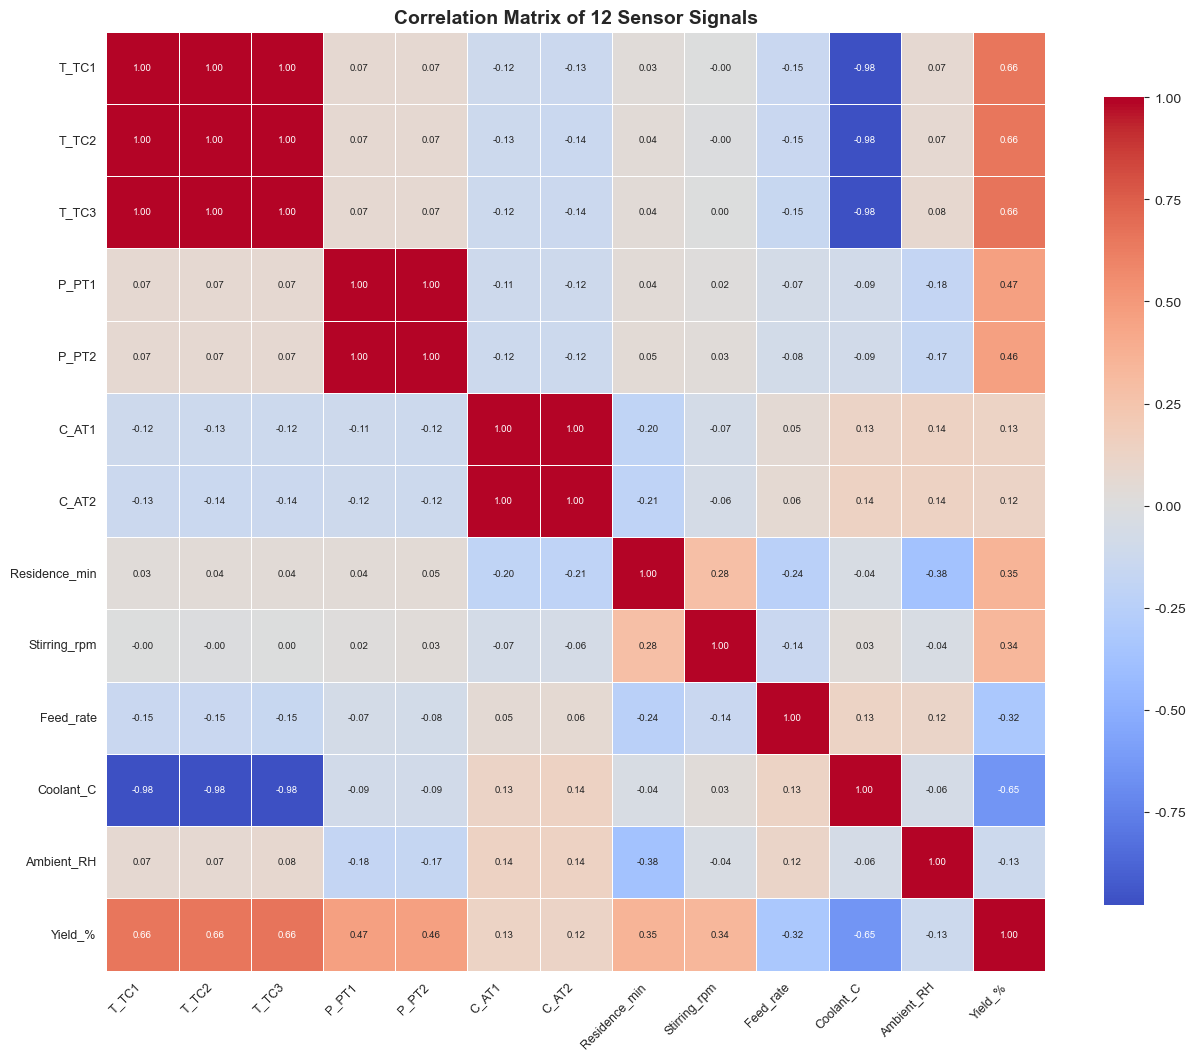

特徵之間相關性最高的前 8 對:
Feature A       Feature B        Correlation
--------------------------------------------
T_TC2           T_TC3                 0.9993
T_TC1           T_TC3                 0.9991
T_TC1           T_TC2                 0.9990
C_AT1           C_AT2                 0.9989
P_PT1           P_PT2                 0.9987
T_TC2           Coolant_C            -0.9779
T_TC1           Coolant_C            -0.9779
T_TC3           Coolant_C            -0.9769

與產率的相關係數（絕對值由大到小）:
T_TC3            0.660833
T_TC1            0.657849
T_TC2            0.655668
Coolant_C        0.647864
P_PT1            0.466171
P_PT2            0.463799
Residence_min    0.354052
Stirring_rpm     0.338290
Feed_rate        0.323169
C_AT1            0.133285
Ambient_RH       0.127320
C_AT2            0.123257


In [6]:
corr = df.corr()

plt.figure(figsize=(13, 11))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            square=True, linewidths=0.5, annot_kws={'size': 7},
            cbar_kws={'shrink': 0.8})
plt.title('Correlation Matrix of 12 Sensor Signals', fontsize=14, fontweight='bold')
plt.xticks(rotation=45, ha='right', fontsize=9)
plt.yticks(fontsize=9)
plt.tight_layout()
plt.savefig(FIG_DIR / 'correlation_matrix.png', dpi=300, bbox_inches='tight')
plt.show()

# 找出特徵之間相關係數絕對值最高的組合
feat_corr = corr.drop(index='Yield_%', columns='Yield_%')
cols = list(feat_corr.columns)
pairs = []
for i in range(len(cols)):
    for j in range(i + 1, len(cols)):
        pairs.append((cols[i], cols[j], feat_corr.iloc[i, j]))

pairs_sorted = sorted(pairs, key=lambda x: abs(x[2]), reverse=True)

print("特徵之間相關性最高的前 8 對:")
print(f"{'Feature A':<16}{'Feature B':<16}{'Correlation':>12}")
print("-" * 44)
for a, b, r in pairs_sorted[:8]:
    print(f"{a:<16}{b:<16}{r:>12.4f}")

print("\n與產率的相關係數（絕對值由大到小）:")
print(corr['Yield_%'].drop('Yield_%').abs().sort_values(ascending=False).to_string())

### 4.2 方差膨脹因子 (VIF)

相關係數只能看出「兩兩」關係，VIF 則衡量「一個特徵被其他所有特徵線性解釋」的程度：

$$
\mathrm{VIF}_j = \frac{1}{1 - R_j^{2}}
$$

其中 $R_j^{2}$ 是把第 $j$ 個特徵對其餘所有特徵做回歸所得的決定係數。

| VIF | 判讀 |
|-----|------|
| $< 5$ | 無明顯共線性 |
| $5 - 10$ | 中度共線性 |
| $> 10$ | 嚴重共線性（係數估計不可信） |
| $> 100$ | 極端共線性（OLS 解幾乎不可辨識） |

方差膨脹因子 (VIF) — 由大到小
      Feature         VIF Severity
        T_TC3 1163.360824  Extreme
        T_TC2  988.250870  Extreme
        T_TC1  741.514753  Extreme
        C_AT2  651.366222  Extreme
        C_AT1  646.713208  Extreme
        P_PT2  428.514427  Extreme
        P_PT1  428.054429  Extreme
    Coolant_C   24.420538   Severe
   Ambient_RH    1.448134       OK
Residence_min    1.443727       OK
 Stirring_rpm    1.342782       OK
    Feed_rate    1.197757       OK

VIF > 100 的特徵數: 7 / 12
最大 VIF: 1163.4  (T_TC3)

結論: 設計矩陣已接近奇異，OLS 係數估計將極不穩定。


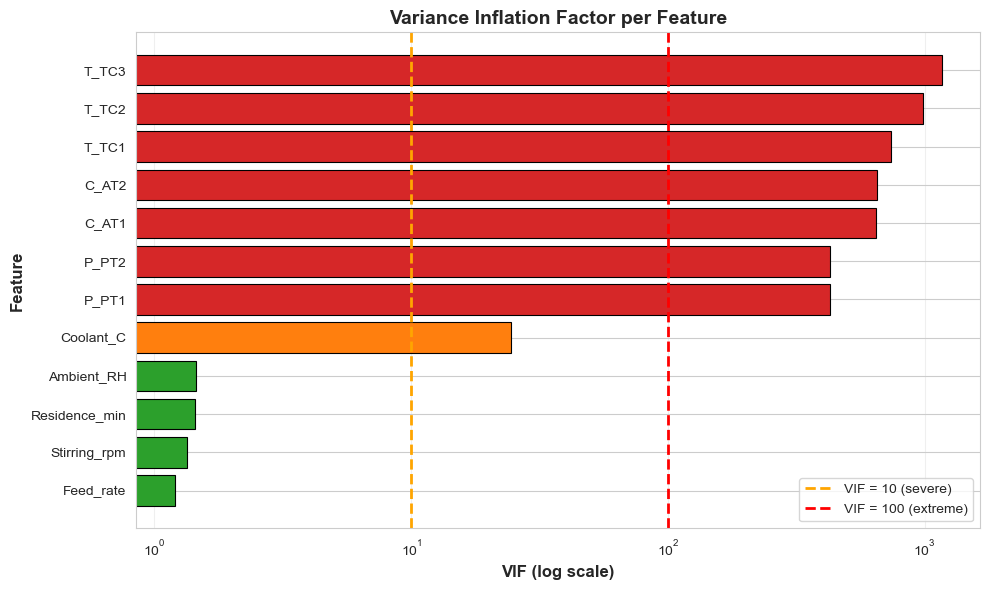

In [4]:
X = df.drop('Yield_%', axis=1)
y = df['Yield_%']

# 計算 VIF（需加入常數項）
X_with_const = sm.add_constant(X)
vif_data = pd.DataFrame({
    'Feature': X.columns,
    'VIF': [variance_inflation_factor(X_with_const.values, i + 1)
            for i in range(X.shape[1])]
})
vif_data['Severity'] = pd.cut(
    vif_data['VIF'],
    bins=[-np.inf, 5, 10, 100, np.inf],
    labels=['OK', 'Moderate', 'Severe', 'Extreme']
)
vif_data = vif_data.sort_values('VIF', ascending=False).reset_index(drop=True)

print("="*62)
print("方差膨脹因子 (VIF) — 由大到小")
print("="*62)
print(vif_data.to_string(index=False))
print("="*62)

n_extreme = (vif_data['VIF'] > 100).sum()
print(f"\nVIF > 100 的特徵數: {n_extreme} / {X.shape[1]}")
print(f"最大 VIF: {vif_data['VIF'].iloc[0]:.1f}  ({vif_data['Feature'].iloc[0]})")
print("\n結論: 設計矩陣已接近奇異，OLS 係數估計將極不穩定。")

# 視覺化
fig, ax = plt.subplots(figsize=(10, 6))
colors = ['#d62728' if v > 100 else '#ff7f0e' if v > 10 else '#2ca02c'
          for v in vif_data['VIF']]
ax.barh(vif_data['Feature'][::-1], vif_data['VIF'][::-1],
        color=colors[::-1], edgecolor='black', linewidth=0.8)
ax.set_xscale('log')
ax.set_xlabel('VIF (log scale)', fontsize=12, fontweight='bold')
ax.set_ylabel('Feature', fontsize=12, fontweight='bold')
ax.set_title('Variance Inflation Factor per Feature', fontsize=14, fontweight='bold')
ax.axvline(x=10, color='orange', linestyle='--', linewidth=2, label='VIF = 10 (severe)')
ax.axvline(x=100, color='red', linestyle='--', linewidth=2, label='VIF = 100 (extreme)')
ax.legend(loc='lower right')
ax.grid(True, alpha=0.3, axis='x')
plt.tight_layout()
plt.savefig(FIG_DIR / 'vif_bar.png', dpi=300, bbox_inches='tight')
plt.show()

---
## 5. 數據預處理

### 5.1 訓練集 / 測試集切分

刻意讓測試集佔 40%，使訓練集只剩 **30 筆樣本要估計 12 個係數**（$n/p = 2.5$）。
這種比例在真實化工廠很常見：新製程上線初期，批次紀錄本來就少。

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.4, random_state=SEED
)

print("✓ 數據切分完成")
print(f"訓練集: {X_train.shape[0]} 筆 x {X_train.shape[1]} 特徵")
print(f"測試集: {X_test.shape[0]} 筆 x {X_test.shape[1]} 特徵")
print(f"訓練集 n/p 比值: {X_train.shape[0] / X_train.shape[1]:.2f}")
print(f"\n統計學經驗法則: n/p < 5 時，OLS 估計誤差會急遽放大")
print(f"                 本案例 n/p = {X_train.shape[0] / X_train.shape[1]:.2f}，屬於高風險區")

✓ 數據切分完成
訓練集: 30 筆 x 12 特徵
測試集: 20 筆 x 12 特徵
訓練集 n/p 比值: 2.50

統計學經驗法則: n/p < 5 時，OLS 估計誤差會急遽放大
                 本案例 n/p = 2.50，屬於高風險區


### 5.2 特徵標準化

**Ridge 必須標準化**，原因有二：

1. 懲罰項 $\alpha \sum \beta_j^{2}$ 對所有係數一視同仁，若特徵尺度不同（溫度 ~100、壓力 ~3），懲罰會嚴重偏向尺度小的特徵
2. 標準化後係數可直接比較「相對重要性」

注意：**只用訓練集計算均值與標準差**，避免測試集資訊洩漏。

In [8]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)   # fit + transform
X_test_scaled = scaler.transform(X_test)         # 只 transform

print("✓ 特徵標準化完成")
print(f"訓練集均值 (應接近 0): {np.round(X_train_scaled.mean(axis=0), 6)}")
print(f"訓練集標準差 (應接近 1): {np.round(X_train_scaled.std(axis=0), 6)}")
print(f"測試集均值: {np.round(X_test_scaled.mean(axis=0), 3)}  (不必然為 0，正常現象)")

✓ 特徵標準化完成
訓練集均值 (應接近 0): [ 0.  0. -0.  0. -0. -0.  0.  0. -0.  0. -0.  0.]
訓練集標準差 (應接近 1): [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
測試集均值: [-0.215 -0.193 -0.197  0.333  0.329  0.23   0.218  0.427  0.316 -0.036
  0.127 -0.478]  (不必然為 0，正常現象)


---
## 6. 使用 RidgeCV 選擇正則化參數 $\alpha$

$\alpha$ 控制偏差與變異數的權衡：

- $\alpha \to 0$：退化為 OLS，變異數最大
- $\alpha$ 增大：係數被壓縮，變異數下降、偏差上升
- $\alpha \to \infty$：所有係數趨近 0，模型只輸出截距

`RidgeCV` 用 K-Fold 交叉驗證在對數網格上搜尋，並以 **留一法（LOO）效率化計算**，不需重複擬合。

**重要**：交叉驗證必須在**訓練集內部**進行，測試集只在最後評估一次。

In [9]:
alphas = np.logspace(-3, 4, 60)

ridge_cv = RidgeCV(alphas=alphas, cv=5, scoring='neg_mean_squared_error')
ridge_cv.fit(X_train_scaled, y_train)
best_alpha = float(ridge_cv.alpha_)

print("="*62)
print("RidgeCV 交叉驗證結果")
print("="*62)
print(f"搜尋範圍: [{alphas.min():.4f}, {alphas.max():.1f}]  (共 {len(alphas)} 個候選)")
print(f"最佳 alpha: {best_alpha:.4f}")
print(f"對應 CV MSE: {-ridge_cv.best_score_:.4f}")
print(f"對應 CV RMSE: {np.sqrt(-ridge_cv.best_score_):.4f}")
print("="*62)

print(f"\n解讀: alpha = {best_alpha:.4f} 屬於「中度正則化」。")
print("      既保留足夠信號，又抑制共線性造成的係數爆炸。")

RidgeCV 交叉驗證結果
搜尋範圍: [0.0010, 10000.0]  (共 60 個候選)
最佳 alpha: 0.4075
對應 CV MSE: 12.1457
對應 CV RMSE: 3.4851

解讀: alpha = 0.4075 屬於「中度正則化」。
      既保留足夠信號，又抑制共線性造成的係數爆炸。


---
## 7. 訓練 Ridge 與 OLS 模型

在同一組標準化資料上訓練兩個模型，其餘條件完全相同，唯一差別是**有沒有 L2 懲罰**。

In [10]:
# Ridge
ridge_model = Ridge(alpha=best_alpha)
ridge_model.fit(X_train_scaled, y_train)

# OLS
ols_model = LinearRegression()
ols_model.fit(X_train_scaled, y_train)

print("✓ 兩個模型皆訓練完成")
print(f"Ridge 截距: {ridge_model.intercept_:.4f}")
print(f"OLS   截距: {ols_model.intercept_:.4f}")
print("(截距不受正則化影響，兩者應相同)")

✓ 兩個模型皆訓練完成
Ridge 截距: 96.4699
OLS   截距: 96.4699
(截距不受正則化影響，兩者應相同)


### 7.1 係數比較：OLS 的失控 vs Ridge 的穩定

這是本 Notebook 的**核心觀察點**。請注意 OLS 係數的**符號**與**量級**。

下表所有係數皆為**標準化特徵尺度**（每 1 標準差的產率變化量），並以理論真實貢獻 `True_Coef` 作為基準。由於冗餘感測器量測同一物理量，真實貢獻由同組感測器均分。

**物理上不可能**的地方：

- 三支熱電偶量測同一個溫度，若溫度對產率是正效應，三個係數應該**同號**
- 催化劑濃度對產率是正效應（原始模型係數 $+5.0$，標準化後約 $+1.5$），不應出現負號
- 冷卻水溫度對產率**沒有因果效應**，其係數應接近 0

OLS 在極端共線性下會把同一份資訊「任意分配」給多個共線特徵，正負相消，產生看似荒謬但數學上等價的解。

In [26]:
# 理論真實貢獻（標準化特徵尺度）：原始模型係數 x 訓練集標準差；
# 冗餘感測器量測同一物理量，故同組均分同一物理效應
_raw_specs = {
    'T_TC1': (0.5, 3), 'T_TC2': (0.5, 3), 'T_TC3': (0.5, 3),
    'P_PT1': (3.0, 2), 'P_PT2': (3.0, 2),
    'C_AT1': (5.0, 2), 'C_AT2': (5.0, 2),
    'Residence_min': (0.05, 1), 'Stirring_rpm': (0.02, 1), 'Feed_rate': (-0.1, 1),
    'Coolant_C': (0.0, 1), 'Ambient_RH': (0.0, 1),
}
train_std = X_train.std(ddof=0)   # 與 StandardScaler 相同的母體標準差
true_coef = [_raw_specs[f][0] * train_std[f] / _raw_specs[f][1] for f in X.columns]

coef_df = pd.DataFrame({
    'Feature': X.columns,
    'True_Coef': true_coef,
    'OLS': ols_model.coef_,
    'Ridge': ridge_model.coef_,
})
coef_df['OLS_abs'] = coef_df['OLS'].abs()
coef_df['Ridge_abs'] = coef_df['Ridge'].abs()

print("="*88)
print("係數比較（皆為標準化特徵尺度，單位：每 1 標準差的產率變化量；")
print("           True_Coef 為理論真實貢獻，冗餘感測器均分同一物理效應）")
print("="*88)
print(coef_df[['Feature', 'True_Coef', 'OLS', 'Ridge']].to_string(index=False,
      float_format=lambda v: f'{v:9.3f}'))
print("="*88)

# --- 量化失控程度 ---
ols_max = coef_df['OLS_abs'].max()
ridge_max = coef_df['Ridge_abs'].max()
print(f"\nOLS   係數絕對值最大: {ols_max:9.2f}")
print(f"Ridge 係數絕對值最大: {ridge_max:9.2f}")
print(f"倍數差距: {ols_max / ridge_max:.1f}x")

# 符號一致性檢查：三支溫度感測器
temp_cols = ['T_TC1', 'T_TC2', 'T_TC3']
ols_temp = coef_df.set_index('Feature').loc[temp_cols, 'OLS']
ridge_temp = coef_df.set_index('Feature').loc[temp_cols, 'Ridge']
print("\n三支溫度感測器的係數:")
print(f"  OLS  : {np.round(ols_temp.values, 2)}  -> 同號? {len(set(np.sign(ols_temp.values))) == 1}")
print(f"  Ridge: {np.round(ridge_temp.values, 2)}  -> 同號? {len(set(np.sign(ridge_temp.values))) == 1}")

# 催化劑符號檢查
cat_cols = ['C_AT1', 'C_AT2']
ols_cat = coef_df.set_index('Feature').loc[cat_cols, 'OLS']
ridge_cat = coef_df.set_index('Feature').loc[cat_cols, 'Ridge']
print("\n兩支催化劑分析儀的係數（真實效應為正）:")
print(f"  OLS  : {np.round(ols_cat.values, 2)}  -> 皆為正? {bool((ols_cat.values > 0).all())}")
print(f"  Ridge: {np.round(ridge_cat.values, 2)}  -> 皆為正? {bool((ridge_cat.values > 0).all())}")

# 冷卻水（無因果效應）
cool_ols = float(coef_df.set_index('Feature').loc['Coolant_C', 'OLS'])
cool_ridge = float(coef_df.set_index('Feature').loc['Coolant_C', 'Ridge'])
print("\n冷卻水溫度係數（真實效應 = 0）:")
print(f"  OLS  : {cool_ols:.3f}   <- 假象效應")
print(f"  Ridge: {cool_ridge:.3f}   <- 更接近 0")

係數比較（皆為標準化特徵尺度，單位：每 1 標準差的產率變化量；
           True_Coef 為理論真實貢獻，冗餘感測器均分同一物理效應）
      Feature  True_Coef       OLS     Ridge
        T_TC1      2.095   -21.632     1.530
        T_TC2      2.080    45.481     2.278
        T_TC3      2.069   -15.974     1.114
        P_PT1      1.904    26.487     2.651
        P_PT2      1.896   -23.443     0.386
        C_AT1      1.460   -18.404     0.304
        C_AT2      1.452    21.511     2.293
Residence_min      2.201     3.489     2.976
 Stirring_rpm      2.177     1.704     1.869
    Feed_rate     -0.293    -1.493    -0.944
    Coolant_C      0.000     1.816    -1.044
   Ambient_RH      0.000     0.370    -0.016

OLS   係數絕對值最大:     45.48
Ridge 係數絕對值最大:      2.98
倍數差距: 15.3x

三支溫度感測器的係數:
  OLS  : [-21.63  45.48 -15.97]  -> 同號? False
  Ridge: [1.53 2.28 1.11]  -> 同號? True

兩支催化劑分析儀的係數（真實效應為正）:
  OLS  : [-18.4   21.51]  -> 皆為正? False
  Ridge: [0.3  2.29]  -> 皆為正? True

冷卻水溫度係數（真實效應 = 0）:
  OLS  : 1.816   <- 假象效應
  Ridge: -1.044   <- 更接近 0


### 7.2 係數視覺化

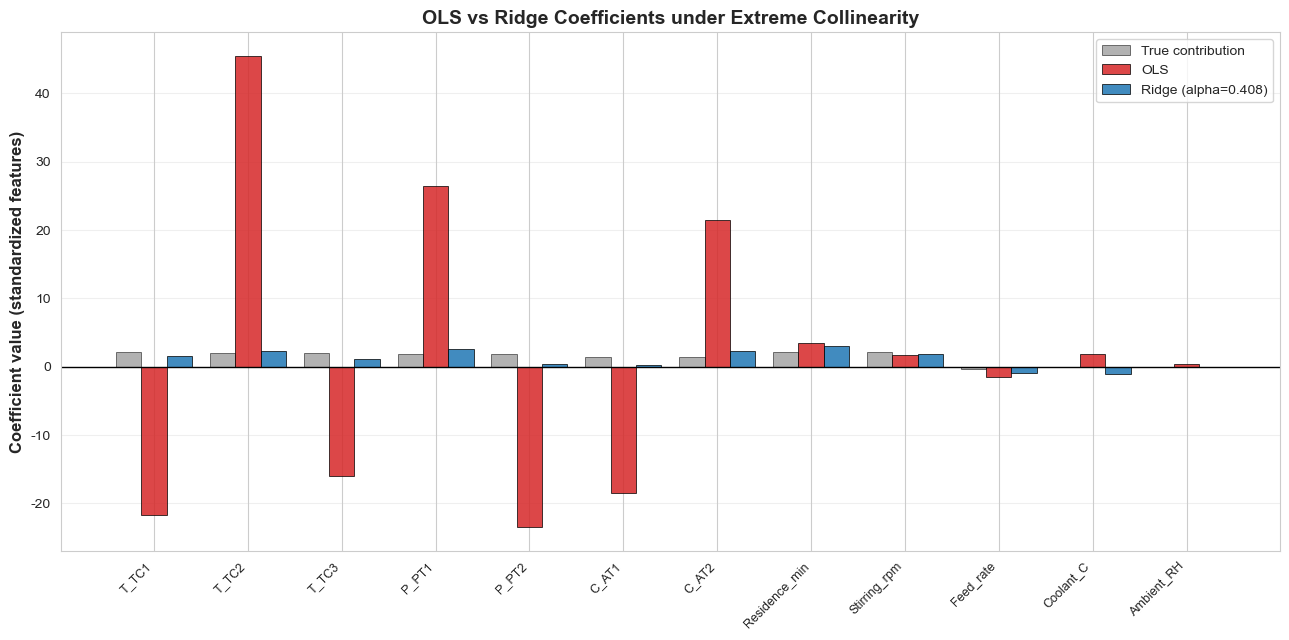

圖中可清楚看到:
  1. OLS 的長條高度遠超真實貢獻，且正負號任意翻轉
  2. Ridge 的長條全部收斂到與真實貢獻相近的量級
  3. Ridge 保留正確的符號方向（溫度、壓力、催化劑皆為正）


In [27]:
fig, ax = plt.subplots(figsize=(13, 6.5))
xpos = np.arange(len(X.columns))
w = 0.27

ax.bar(xpos - w, coef_df['True_Coef'], w, label='True contribution',
       color='#7f7f7f', alpha=0.6, edgecolor='black', linewidth=0.6)
ax.bar(xpos, coef_df['OLS'], w, label='OLS', color='#d62728',
       alpha=0.85, edgecolor='black', linewidth=0.6)
ax.bar(xpos + w, coef_df['Ridge'], w, label=f'Ridge (alpha={best_alpha:.3f})',
       color='#1f77b4', alpha=0.85, edgecolor='black', linewidth=0.6)

ax.axhline(y=0, color='black', linewidth=1)
ax.set_xticks(xpos)
ax.set_xticklabels(X.columns, rotation=45, ha='right', fontsize=9)
ax.set_ylabel('Coefficient value (standardized features)', fontsize=12, fontweight='bold')
ax.set_title('OLS vs Ridge Coefficients under Extreme Collinearity', fontsize=14, fontweight='bold')
ax.legend(loc='upper right', fontsize=10)
ax.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig(FIG_DIR / 'coefficient_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

print("圖中可清楚看到:")
print("  1. OLS 的長條高度遠超真實貢獻，且正負號任意翻轉")
print("  2. Ridge 的長條全部收斂到與真實貢獻相近的量級")
print("  3. Ridge 保留正確的符號方向（溫度、壓力、催化劑皆為正）")

---
## 8. 泛化能力比較

係數穩定只是第一步，真正要問的是：**哪個模型對新批次的預測更準？**

評估指標：
- $R^2$：解釋變異的能力（越高越好）
- RMSE：預測誤差的絕對量級，與產率同單位（%）
- MAE：平均絕對誤差，對離群值較不敏感

In [13]:
def evaluate(model, name):
    tr_pred = model.predict(X_train_scaled)
    te_pred = model.predict(X_test_scaled)
    return {
        'Model': name,
        'Train_R2': r2_score(y_train, tr_pred),
        'Test_R2': r2_score(y_test, te_pred),
        'Train_RMSE': np.sqrt(mean_squared_error(y_train, tr_pred)),
        'Test_RMSE': np.sqrt(mean_squared_error(y_test, te_pred)),
        'Test_MAE': mean_absolute_error(y_test, te_pred),
    }

perf = pd.DataFrame([evaluate(ols_model, 'OLS'), evaluate(ridge_model, 'Ridge')])

print("="*82)
print("模型性能比較")
print("="*82)
print(perf.to_string(index=False, float_format=lambda v: f'{v:.4f}'))
print("="*82)

ols_test_r2 = perf.loc[0, 'Test_R2']
ridge_test_r2 = perf.loc[1, 'Test_R2']
ols_test_rmse = perf.loc[0, 'Test_RMSE']
ridge_test_rmse = perf.loc[1, 'Test_RMSE']

print("\n【關鍵對比】")
print(f"  測試集 R2   : OLS {ols_test_r2:.4f}  ->  Ridge {ridge_test_r2:.4f}"
      f"   (提升 {ridge_test_r2 - ols_test_r2:+.4f})")
print(f"  測試集 RMSE : OLS {ols_test_rmse:.4f}  ->  Ridge {ridge_test_rmse:.4f}"
      f"   (降低 {ols_test_rmse - ridge_test_rmse:.4f})")
print(f"  測試集誤差改善幅度: {(ols_test_rmse - ridge_test_rmse) / ols_test_rmse * 100:.1f}%")

print("\n【過擬合診斷】")
for _, r in perf.iterrows():
    gap = r['Train_R2'] - r['Test_R2']
    print(f"  {r['Model']:<6}: Train-Test R2 差距 = {gap:.4f}")
print("\nOLS 的 Train-Test 差距明顯較大，代表它記住了訓練集雜訊（過擬合）。")
print("Ridge 的差距較小，泛化更穩健。")

模型性能比較
Model  Train_R2  Test_R2  Train_RMSE  Test_RMSE  Test_MAE
  OLS    0.9241   0.7369      2.2971     4.5072    3.2293
Ridge    0.8978   0.8602      2.6667     3.2851    2.4819

【關鍵對比】
  測試集 R2   : OLS 0.7369  ->  Ridge 0.8602   (提升 +0.1234)
  測試集 RMSE : OLS 4.5072  ->  Ridge 3.2851   (降低 1.2221)
  測試集誤差改善幅度: 27.1%

【過擬合診斷】
  OLS   : Train-Test R2 差距 = 0.1873
  Ridge : Train-Test R2 差距 = 0.0376

OLS 的 Train-Test 差距明顯較大，代表它記住了訓練集雜訊（過擬合）。
Ridge 的差距較小，泛化更穩健。


---
## 9. Bootstrap 係數穩定性分析

單一次切分的結果可能只是運氣。**Bootstrap** 提供更嚴謹的證據：

1. 從訓練集**有放回**抽取 30 筆樣本
2. 重複擬合 OLS 與 Ridge
3. 觀察每個係數的分布寬度

若某個係數的 Bootstrap 標準差很大，代表**換一批資料，結論就會改變**，這種係數不能用於工程判斷或控制策略設計。

In [14]:
rng = np.random.default_rng(SEED)
N_BOOT = 300
y_train_arr = np.asarray(y_train)

ols_boot = np.zeros((N_BOOT, X.shape[1]))
ridge_boot = np.zeros((N_BOOT, X.shape[1]))
n_ok = 0

for b in range(N_BOOT):
    idx = rng.integers(0, len(y_train_arr), len(y_train_arr))
    Xb = X_train_scaled[idx]
    yb = y_train_arr[idx]

    # 略過退化樣本（重複點過多導致奇異）
    if np.linalg.matrix_rank(Xb) < Xb.shape[1]:
        continue

    ols_boot[n_ok] = LinearRegression().fit(Xb, yb).coef_
    ridge_boot[n_ok] = Ridge(alpha=best_alpha).fit(Xb, yb).coef_
    n_ok += 1

ols_boot = ols_boot[:n_ok]
ridge_boot = ridge_boot[:n_ok]

print(f"✓ Bootstrap 完成: {n_ok} / {N_BOOT} 次成功擬合")

boot_df = pd.DataFrame({
    'Feature': X.columns,
    'OLS_std': ols_boot.std(axis=0),
    'Ridge_std': ridge_boot.std(axis=0),
})
boot_df['Ratio_OLS_over_Ridge'] = boot_df['OLS_std'] / boot_df['Ridge_std']

print("\n" + "="*86)
print("係數的 Bootstrap 標準差（越小越穩定）")
print("="*86)
print(boot_df.to_string(index=False, float_format=lambda v: f'{v:.3f}'))
print("="*86)

print(f"\n平均 Bootstrap 標準差:")
print(f"  OLS  : {boot_df['OLS_std'].mean():.3f}")
print(f"  Ridge: {boot_df['Ridge_std'].mean():.3f}")
print(f"  穩定度改善: {boot_df['Ratio_OLS_over_Ridge'].mean():.1f}x")

print(f"\nOLS 係數在 Bootstrap 中的最大絕對值: {np.abs(ols_boot).max():.1f}")
print(f"Ridge 係數在 Bootstrap 中的最大絕對值: {np.abs(ridge_boot).max():.1f}")
print("\n=> OLS 可能出現量級達數百的係數，完全脫離物理意義。")
print("=> Ridge 的係數始終維持在合理範圍。")

✓ Bootstrap 完成: 300 / 300 次成功擬合

係數的 Bootstrap 標準差（越小越穩定）
      Feature  OLS_std  Ridge_std  Ratio_OLS_over_Ridge
        T_TC1   45.315      0.767                59.050
        T_TC2   44.585      0.764                58.353
        T_TC3   63.761      0.791                80.636
        P_PT1   20.075      0.834                24.073
        P_PT2   19.768      0.758                26.089
        C_AT1   50.618      0.704                71.933
        C_AT2   50.827      0.645                78.850
Residence_min    1.309      0.808                 1.620
 Stirring_rpm    1.955      0.740                 2.641
    Feed_rate    1.358      0.650                 2.091
    Coolant_C    5.460      1.783                 3.062
   Ambient_RH    1.869      0.836                 2.237

平均 Bootstrap 標準差:
  OLS  : 25.575
  Ridge: 0.840
  穩定度改善: 34.2x

OLS 係數在 Bootstrap 中的最大絕對值: 918.0
Ridge 係數在 Bootstrap 中的最大絕對值: 6.2

=> OLS 可能出現量級達數百的係數，完全脫離物理意義。
=> Ridge 的係數始終維持在合理範圍。


### 9.1 Bootstrap 係數分布視覺化

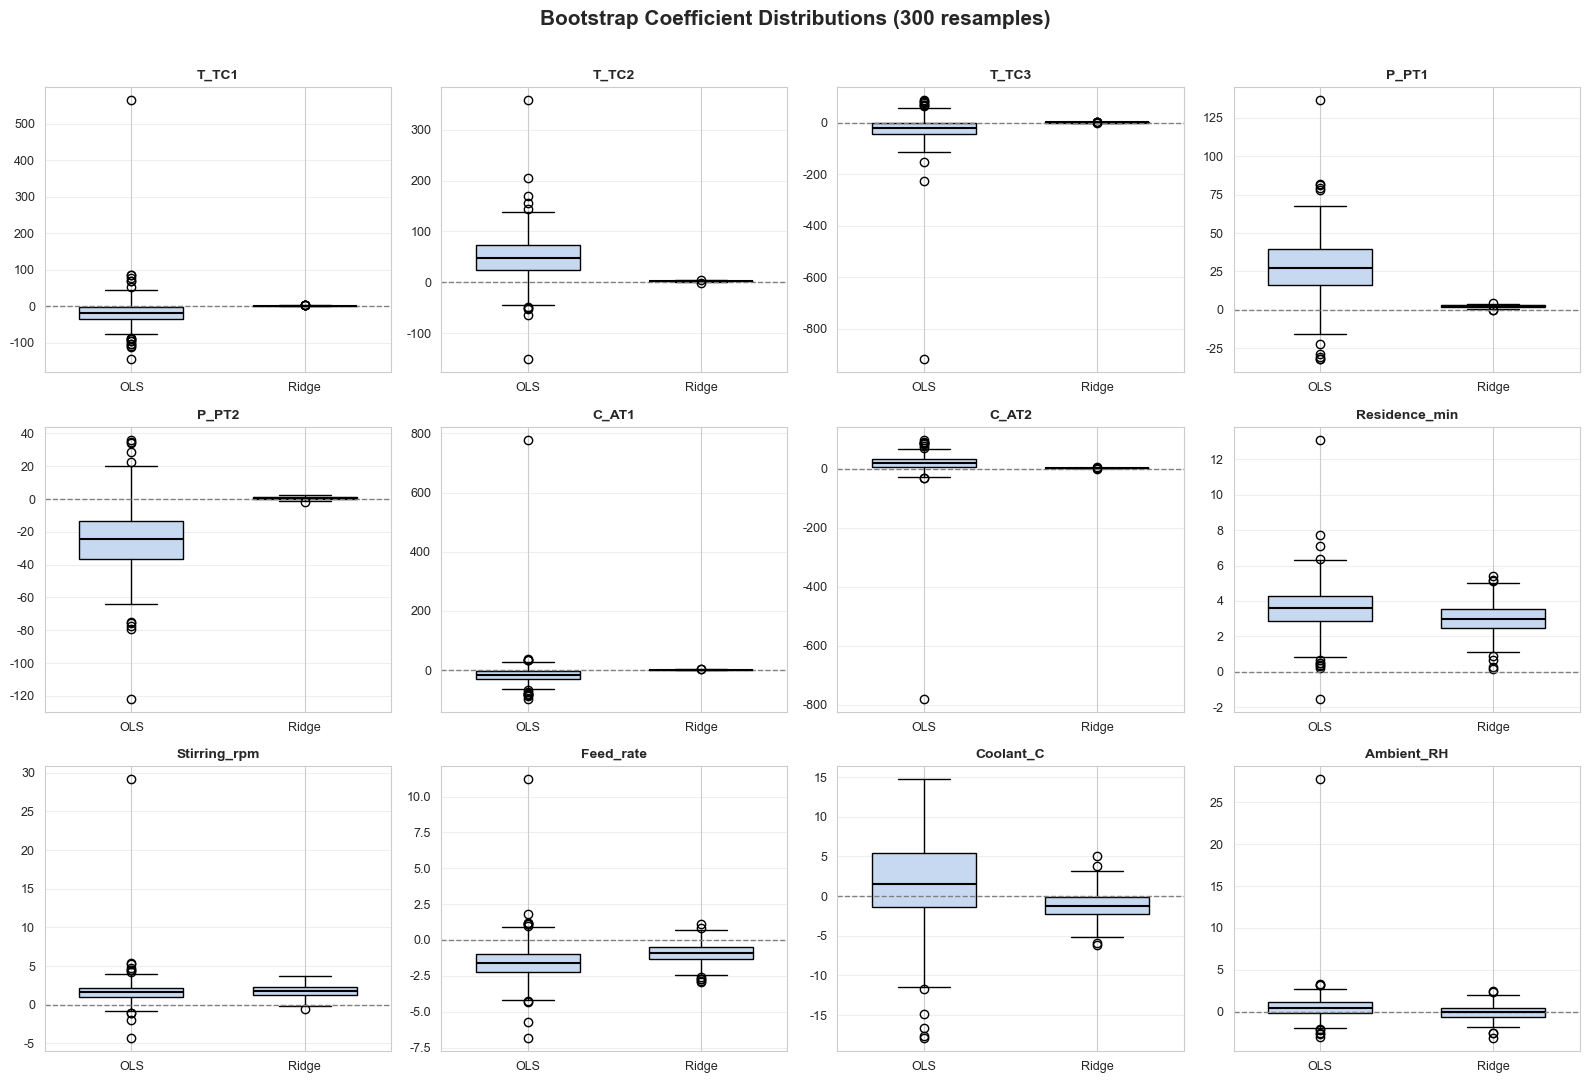

觀察重點:
  - OLS 的箱型圖（左）又長又分散，部分甚至跨越 0 大幅擺盪
  - Ridge 的箱型圖（右）被壓縮成窄窄一條，幾乎沒有變異
  - 共線性特徵（T_TC1/2/3、P_PT1/2、C_AT1/2）差異最明顯


In [15]:
fig, axes = plt.subplots(3, 4, figsize=(16, 11), sharex=False)
axes = axes.ravel()

for j, feat in enumerate(X.columns):
    ax = axes[j]
    ax.boxplot([ols_boot[:, j], ridge_boot[:, j]],
               labels=['OLS', 'Ridge'], widths=0.6,
               patch_artist=True,
               boxprops=dict(facecolor='#c7d9f0'),
               medianprops=dict(color='black', linewidth=1.5))
    ax.axhline(y=0, color='gray', linestyle='--', linewidth=1)
    ax.set_title(feat, fontsize=10, fontweight='bold')
    ax.grid(True, alpha=0.3, axis='y')
    ax.tick_params(labelsize=9)

for k in range(len(X.columns), len(axes)):
    axes[k].axis('off')

plt.suptitle('Bootstrap Coefficient Distributions (300 resamples)', fontsize=15, fontweight='bold')
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.savefig(FIG_DIR / 'bootstrap_coefficients.png', dpi=300, bbox_inches='tight')
plt.show()

print("觀察重點:")
print("  - OLS 的箱型圖（左）又長又分散，部分甚至跨越 0 大幅擺盪")
print("  - Ridge 的箱型圖（右）被壓縮成窄窄一條，幾乎沒有變異")
print("  - 共線性特徵（T_TC1/2/3、P_PT1/2、C_AT1/2）差異最明顯")

---
## 10. 正則化路徑：alpha 如何影響係數

把 $\alpha$ 從極小掃到極大，觀察係數的收縮軌跡。

**Ridge 路徑的特性**：係數隨 $\alpha$ 增大而**平滑單調地趨近 0**（不會突然歸零，這是與 Lasso 最大的差異）。

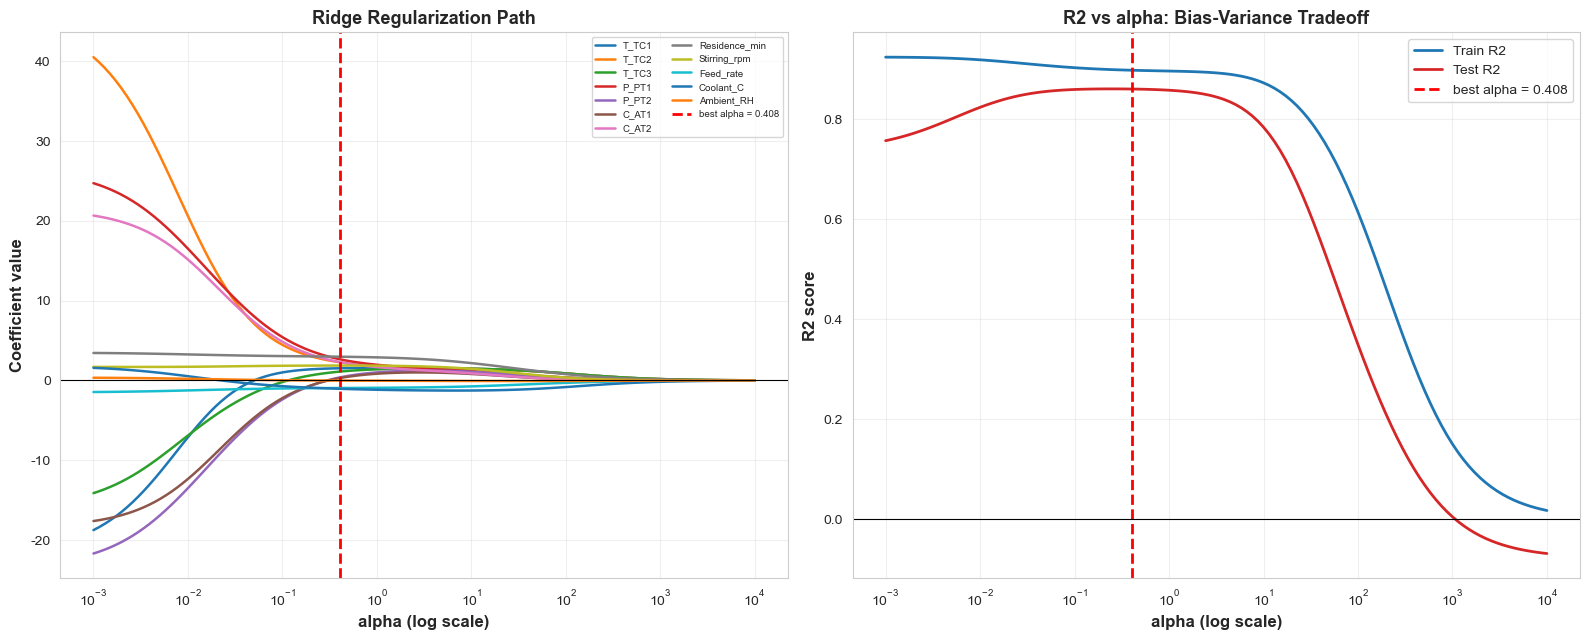

訓練集 R2 在 alpha 極小時最高: 0.9240
測試集 R2 的峰值出現在 alpha = 0.2581  (R2 = 0.8605)
RidgeCV 選出的 alpha = 0.4075  (Test R2 = 0.8603)

注意: 左圖在 alpha 極小時係數劇烈擺盪（接近 OLS 的失控解），
      alpha 增大後才收斂成平滑曲線。這正是 Ridge 抑制共線性的機制。


In [16]:
alphas_path = np.logspace(-3, 4, 120)
coef_path = np.zeros((len(alphas_path), X.shape[1]))
train_r2_path = np.zeros(len(alphas_path))
test_r2_path = np.zeros(len(alphas_path))

for i, a in enumerate(alphas_path):
    m = Ridge(alpha=a).fit(X_train_scaled, y_train)
    coef_path[i] = m.coef_
    train_r2_path[i] = r2_score(y_train, m.predict(X_train_scaled))
    test_r2_path[i] = r2_score(y_test, m.predict(X_test_scaled))

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))

# 左：係數路徑
for j, feat in enumerate(X.columns):
    axes[0].plot(alphas_path, coef_path[:, j], label=feat, linewidth=1.8)
axes[0].set_xscale('log')
axes[0].axvline(best_alpha, color='red', linestyle='--', linewidth=2,
                label=f'best alpha = {best_alpha:.3f}')
axes[0].axhline(y=0, color='black', linewidth=0.8)
axes[0].set_xlabel('alpha (log scale)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Coefficient value', fontsize=12, fontweight='bold')
axes[0].set_title('Ridge Regularization Path', fontsize=13, fontweight='bold')
axes[0].legend(fontsize=7, ncol=2, loc='upper right')
axes[0].grid(True, alpha=0.3)

# 右：R2 隨 alpha 變化
axes[1].plot(alphas_path, train_r2_path, label='Train R2', linewidth=2, color='#1f77b4')
axes[1].plot(alphas_path, test_r2_path, label='Test R2', linewidth=2, color='#d62728')
axes[1].axvline(best_alpha, color='red', linestyle='--', linewidth=2,
                label=f'best alpha = {best_alpha:.3f}')
axes[1].axhline(y=0, color='black', linewidth=0.8)
axes[1].set_xscale('log')
axes[1].set_xlabel('alpha (log scale)', fontsize=12, fontweight='bold')
axes[1].set_ylabel('R2 score', fontsize=12, fontweight='bold')
axes[1].set_title('R2 vs alpha: Bias-Variance Tradeoff', fontsize=13, fontweight='bold')
axes[1].legend(fontsize=10)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(FIG_DIR / 'regularization_path.png', dpi=300, bbox_inches='tight')
plt.show()

# 找出測試集最佳 alpha（僅供診斷，不可用於模型選擇）
best_test_idx = int(np.argmax(test_r2_path))
print(f"訓練集 R2 在 alpha 極小時最高: {train_r2_path[0]:.4f}")
print(f"測試集 R2 的峰值出現在 alpha = {alphas_path[best_test_idx]:.4f}"
      f"  (R2 = {test_r2_path[best_test_idx]:.4f})")
print(f"RidgeCV 選出的 alpha = {best_alpha:.4f}  (Test R2 = {test_r2_path[np.argmin(np.abs(alphas_path - best_alpha))]:.4f})")
print("\n注意: 左圖在 alpha 極小時係數劇烈擺盪（接近 OLS 的失控解），")
print("      alpha 增大後才收斂成平滑曲線。這正是 Ridge 抑制共線性的機制。")

### 10.1 alpha 掃描定量表

In [17]:
sweep_alphas = sorted(set([0.001, 0.01, 0.1, 0.3, 1.0, 3.0, 10.0, 30.0,
                           100.0, 1000.0, best_alpha]))
rows = []
for a in sweep_alphas:
    m = Ridge(alpha=a).fit(X_train_scaled, y_train)
    rows.append({
        'alpha': a,
        'Train_R2': r2_score(y_train, m.predict(X_train_scaled)),
        'Test_R2': r2_score(y_test, m.predict(X_test_scaled)),
        'Test_RMSE': np.sqrt(mean_squared_error(y_test, m.predict(X_test_scaled))),
        'Max_abs_coef': np.abs(m.coef_).max(),
    })

sweep_df = pd.DataFrame(rows)
print("="*78)
print("Ridge alpha 掃描（* 標記為 RidgeCV 選出的最佳值）")
print("="*78)
for _, r in sweep_df.iterrows():
    mark = ' *' if abs(r['alpha'] - best_alpha) < 1e-6 else ''
    print(f"alpha={r['alpha']:>8.3f}{mark:<3} Train_R2={r['Train_R2']:.4f}  "
          f"Test_R2={r['Test_R2']:.4f}  Test_RMSE={r['Test_RMSE']:7.4f}  "
          f"|coef|max={r['Max_abs_coef']:8.3f}")
print("="*78)
print("\n解讀:")
print("  alpha 太小  -> 係數仍然爆炸 (|coef|max 很大)，Test R2 偏低")
print("  alpha 適中  -> 係數收斂，Test R2 最佳")
print("  alpha 太大  -> 係數被過度壓縮，Train/Test R2 雙雙崩落（欠擬合）")

Ridge alpha 掃描（* 標記為 RidgeCV 選出的最佳值）
alpha=   0.001    Train_R2=0.9240  Test_R2=0.7569  Test_RMSE= 4.3323  |coef|max=  40.517
alpha=   0.010    Train_R2=0.9186  Test_R2=0.8236  Test_RMSE= 3.6902  |coef|max=  20.604
alpha=   0.100    Train_R2=0.9029  Test_R2=0.8593  Test_RMSE= 3.2959  |coef|max=   5.429
alpha=   0.300    Train_R2=0.8985  Test_R2=0.8605  Test_RMSE= 3.2822  |coef|max=   3.029
alpha=   0.408 *  Train_R2=0.8978  Test_R2=0.8602  Test_RMSE= 3.2851  |coef|max=   2.976
alpha=   1.000    Train_R2=0.8962  Test_R2=0.8578  Test_RMSE= 3.3131  |coef|max=   2.895
alpha=   3.000    Train_R2=0.8928  Test_R2=0.8456  Test_RMSE= 3.4529  |coef|max=   2.678
alpha=  10.000    Train_R2=0.8726  Test_R2=0.7840  Test_RMSE= 4.0838  |coef|max=   2.174
alpha=  30.000    Train_R2=0.8005  Test_R2=0.6184  Test_RMSE= 5.4278  |coef|max=   1.498
alpha= 100.000    Train_R2=0.6140  Test_R2=0.3492  Test_RMSE= 7.0882  |coef|max=   0.886
alpha=1000.000    Train_R2=0.1504  Test_R2=0.0049  Test_RMSE= 8.7649  |co

---
## 11. 重複隨機切分：排除「單次切分運氣好」的可能

第 8 節只用了**一次**切分。若 Ridge 只在這次切分贏，說服力不足。

這裡改用 **20 次不同的隨機切分**（每次 60/40），統計 Ridge 勝出的次數與平均差距。

20 次隨機切分的測試集表現
 split   alpha  OLS_Test_R2  Ridge_Test_R2  R2_gain
     0  0.0010       0.6882         0.6930   0.0048
     1  3.6251       0.8019         0.8682   0.0663
     2  3.6251       0.7326         0.7089  -0.0237
     3  4.7639       0.8078         0.8316   0.0238
     4  4.7639       0.8437         0.8628   0.0190
     5  1.5973       0.7918         0.7984   0.0066
     6  0.0265       0.6484         0.6424  -0.0061
     7  4.7639       0.8644         0.8367  -0.0276
     8  2.7585       0.7888         0.8188   0.0299
     9  2.7585       0.8179         0.8604   0.0425
    10  8.2272       0.8166         0.8285   0.0119
    11 10.8118       0.7094         0.8429   0.1336
    12  0.0068       0.7893         0.8016   0.0122
    13  2.7585       0.7181         0.7128  -0.0053
    14  6.2605       0.7519         0.7944   0.0425
    15  2.7585       0.7099         0.7464   0.0364
    16  4.7639       0.7104         0.7365   0.0261
    17  6.2605       0.8558         0.8709   0.01

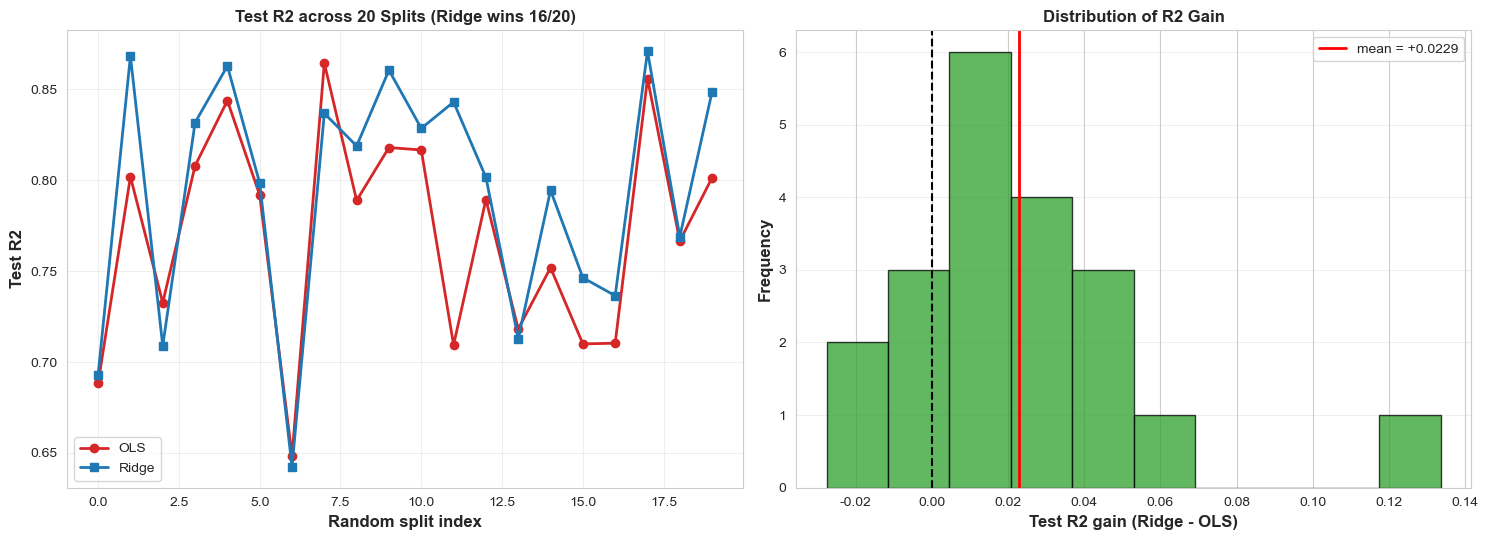


結論: Ridge 不是靠單次切分僥倖勝出，而是系統性地更穩定。


In [18]:
N_SPLITS = 20
split_rows = []

for s in range(N_SPLITS):
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.4, random_state=s)

    sc = StandardScaler()
    Xtr_s = sc.fit_transform(Xtr)
    Xte_s = sc.transform(Xte)

    ols = LinearRegression().fit(Xtr_s, ytr)
    rcv = RidgeCV(alphas=np.logspace(-3, 4, 60), cv=5,
                  scoring='neg_mean_squared_error').fit(Xtr_s, ytr)
    rdg = Ridge(alpha=rcv.alpha_).fit(Xtr_s, ytr)

    split_rows.append({
        'split': s,
        'alpha': rcv.alpha_,
        'OLS_Test_R2': r2_score(yte, ols.predict(Xte_s)),
        'Ridge_Test_R2': r2_score(yte, rdg.predict(Xte_s)),
        'OLS_Test_RMSE': np.sqrt(mean_squared_error(yte, ols.predict(Xte_s))),
        'Ridge_Test_RMSE': np.sqrt(mean_squared_error(yte, rdg.predict(Xte_s))),
    })

split_df = pd.DataFrame(split_rows)
split_df['R2_gain'] = split_df['Ridge_Test_R2'] - split_df['OLS_Test_R2']
split_df['RMSE_reduction_pct'] = (split_df['OLS_Test_RMSE'] - split_df['Ridge_Test_RMSE']) / split_df['OLS_Test_RMSE'] * 100

print("="*92)
print("20 次隨機切分的測試集表現")
print("="*92)
print(split_df[['split', 'alpha', 'OLS_Test_R2', 'Ridge_Test_R2', 'R2_gain']]
      .to_string(index=False, float_format=lambda v: f'{v:.4f}'))
print("="*92)

ridge_wins = int((split_df['R2_gain'] > 0).sum())
print(f"\nRidge 勝出次數: {ridge_wins} / {N_SPLITS}")
print(f"平均 R2 提升: {split_df['R2_gain'].mean():+.4f}  (中位數 {split_df['R2_gain'].median():+.4f})")
print(f"平均 RMSE 降幅: {split_df['RMSE_reduction_pct'].mean():.2f}%")
print(f"R2 提升的最大值: {split_df['R2_gain'].max():+.4f}   最小值: {split_df['R2_gain'].min():+.4f}")

# 視覺化
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

axes[0].plot(split_df['split'], split_df['OLS_Test_R2'], marker='o', label='OLS',
             color='#d62728', linewidth=2)
axes[0].plot(split_df['split'], split_df['Ridge_Test_R2'], marker='s', label='Ridge',
             color='#1f77b4', linewidth=2)
axes[0].set_xlabel('Random split index', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Test R2', fontsize=12, fontweight='bold')
axes[0].set_title(f'Test R2 across 20 Splits (Ridge wins {ridge_wins}/{N_SPLITS})',
                  fontsize=12, fontweight='bold')
axes[0].legend(fontsize=10)
axes[0].grid(True, alpha=0.3)

axes[1].hist(split_df['R2_gain'], bins=10, color='#2ca02c',
             edgecolor='black', alpha=0.75)
axes[1].axvline(x=0, color='black', linewidth=1.5, linestyle='--')
axes[1].axvline(x=split_df['R2_gain'].mean(), color='red', linewidth=2,
                linestyle='-', label=f"mean = {split_df['R2_gain'].mean():+.4f}")
axes[1].set_xlabel('Test R2 gain (Ridge - OLS)', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Frequency', fontsize=12, fontweight='bold')
axes[1].set_title('Distribution of R2 Gain', fontsize=12, fontweight='bold')
axes[1].legend(fontsize=10)
axes[1].grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig(FIG_DIR / 'repeated_splits.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n結論: Ridge 不是靠單次切分僥倖勝出，而是系統性地更穩定。")

---
## 12. 樣本數掃描：Ridge 優勢隨資料量消退

這是理解 Ridge **適用邊界**的關鍵實驗。

固定特徵數（12 個）與共線性結構，只改變樣本數 $n$：

- $n$ 小時，OLS 變異數爆炸，Ridge 大幅領先
- $n$ 增大後，OLS 估計趨於穩定，Ridge 的偏差反而變成負擔
- 兩條曲線最終交會 → **Ridge 不是永遠比較好**

這正是原範例（$n=500$）看不到差異的根本原因。

樣本數掃描（固定 12 特徵、相同共線性結構）
 n_total  n_train  alpha  OLS_Test_R2  Ridge_Test_R2  OLS_max_coef  Ridge_max_coef  R2_gain
      20       12 4.7639      -2.2104         0.6704       67.5043          2.5500   2.8808
      30       18 2.7585      -2.1726        -0.5418       31.7559          2.1551   1.6307
      40       24 1.2155       0.7866         0.8240       28.3331          3.1480   0.0374
      50       30 0.4075       0.7369         0.8602       45.4807          2.9762   0.1234
      70       42 0.1366       0.9007         0.8856       21.1780          5.6314  -0.0150
     100       60 0.1796       0.8307         0.8517       22.0910          6.2157   0.0211
     150       90 4.7639       0.8819         0.8720       11.6820          2.1583  -0.0099
     200      120 1.2155       0.8371         0.8427       12.7165          2.5789   0.0056
     300      180 4.7639       0.8430         0.8392        8.5787          2.6435  -0.0038
     500      300 0.0791       0.8528         0.8541    

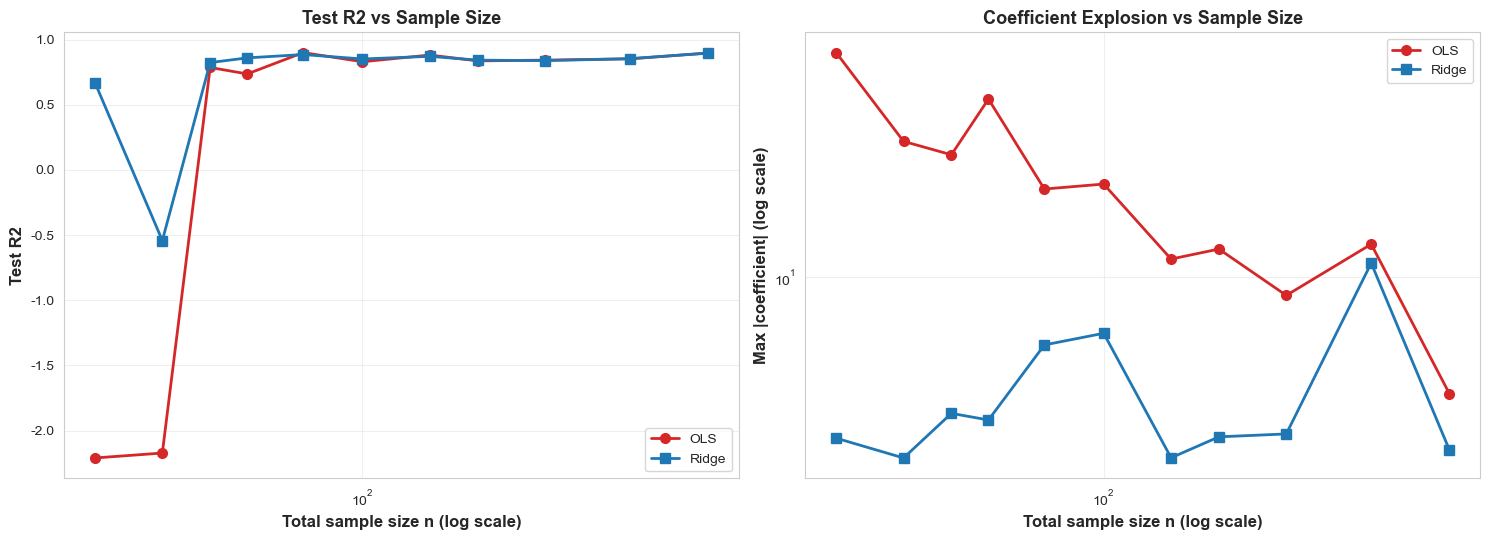


n <= 50  : 平均 R2 提升 +1.1681
n >= 300 : 平均 R2 提升 -0.0009

=> 樣本少時 Ridge 明顯領先；樣本充足後優勢消失（甚至略輸）。
   這解釋了為什麼原範例（n=500）的 OLS 與 Ridge 幾乎相同。


In [19]:
sample_sizes = [20, 30, 40, 50, 70, 100, 150, 200, 300, 500, 800]
sweep_rows = []

for n in sample_sizes:
    # 用固定種子重建 n 筆資料（同樣的生成機制）
    np.random.seed(SEED)
    Tn = np.random.uniform(80, 120, n)
    Pn = np.random.uniform(1, 5, n)
    Cn = np.random.uniform(0.5, 2.5, n)
    tn = np.random.uniform(30, 180, n)
    rpmn = np.random.uniform(200, 600, n)
    Fn = np.random.uniform(5, 15, n)

    dfn = pd.DataFrame({
        'T_TC1': Tn + np.random.normal(0, 0.4, n),
        'T_TC2': Tn + np.random.normal(0, 0.4, n),
        'T_TC3': Tn + np.random.normal(0, 0.4, n),
        'P_PT1': Pn + np.random.normal(0, 0.04, n),
        'P_PT2': Pn + np.random.normal(0, 0.04, n),
        'C_AT1': Cn + np.random.normal(0, 0.02, n),
        'C_AT2': Cn + np.random.normal(0, 0.02, n),
        'Residence_min': tn,
        'Stirring_rpm': rpmn,
        'Feed_rate': Fn,
        'Coolant_C': 60 - 0.8 * Tn + np.random.normal(0, 2, n),
        'Ambient_RH': np.random.uniform(30, 70, n),
    })
    yn = (20.0 + 0.5 * Tn + 3.0 * Pn + 5.0 * Cn + 0.05 * tn
          + 0.02 * rpmn - 0.1 * Fn + np.random.normal(0, 3.0, n))
    dfn['Yield_%'] = yn

    Xn = dfn.drop('Yield_%', axis=1)
    Xtr, Xte, ytr, yte = train_test_split(Xn, yn, test_size=0.4, random_state=SEED)

    sc = StandardScaler()
    Xtr_s = sc.fit_transform(Xtr)
    Xte_s = sc.transform(Xte)

    ols = LinearRegression().fit(Xtr_s, ytr)
    rcv = RidgeCV(alphas=np.logspace(-3, 4, 60), cv=5,
                  scoring='neg_mean_squared_error').fit(Xtr_s, ytr)
    rdg = Ridge(alpha=rcv.alpha_).fit(Xtr_s, ytr)

    sweep_rows.append({
        'n_total': n,
        'n_train': Xtr.shape[0],
        'alpha': rcv.alpha_,
        'OLS_Test_R2': r2_score(yte, ols.predict(Xte_s)),
        'Ridge_Test_R2': r2_score(yte, rdg.predict(Xte_s)),
        'OLS_max_coef': np.abs(ols.coef_).max(),
        'Ridge_max_coef': np.abs(rdg.coef_).max(),
    })

size_df = pd.DataFrame(sweep_rows)
size_df['R2_gain'] = size_df['Ridge_Test_R2'] - size_df['OLS_Test_R2']

print("="*100)
print("樣本數掃描（固定 12 特徵、相同共線性結構）")
print("="*100)
print(size_df.to_string(index=False, float_format=lambda v: f'{v:.4f}'))
print("="*100)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

axes[0].plot(size_df['n_total'], size_df['OLS_Test_R2'], marker='o', label='OLS',
             color='#d62728', linewidth=2, markersize=7)
axes[0].plot(size_df['n_total'], size_df['Ridge_Test_R2'], marker='s', label='Ridge',
             color='#1f77b4', linewidth=2, markersize=7)
axes[0].set_xscale('log')
axes[0].set_xlabel('Total sample size n (log scale)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Test R2', fontsize=12, fontweight='bold')
axes[0].set_title('Test R2 vs Sample Size', fontsize=13, fontweight='bold')
axes[0].legend(fontsize=10)
axes[0].grid(True, alpha=0.3)

axes[1].plot(size_df['n_total'], size_df['OLS_max_coef'], marker='o', label='OLS',
             color='#d62728', linewidth=2, markersize=7)
axes[1].plot(size_df['n_total'], size_df['Ridge_max_coef'], marker='s', label='Ridge',
             color='#1f77b4', linewidth=2, markersize=7)
axes[1].set_xscale('log')
axes[1].set_yscale('log')
axes[1].set_xlabel('Total sample size n (log scale)', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Max |coefficient| (log scale)', fontsize=12, fontweight='bold')
axes[1].set_title('Coefficient Explosion vs Sample Size', fontsize=13, fontweight='bold')
axes[1].legend(fontsize=10)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(FIG_DIR / 'sample_size_sweep.png', dpi=300, bbox_inches='tight')
plt.show()

small = size_df[size_df['n_total'] <= 50]
large = size_df[size_df['n_total'] >= 300]
print(f"\nn <= 50  : 平均 R2 提升 {small['R2_gain'].mean():+.4f}")
print(f"n >= 300 : 平均 R2 提升 {large['R2_gain'].mean():+.4f}")
print("\n=> 樣本少時 Ridge 明顯領先；樣本充足後優勢消失（甚至略輸）。")
print("   這解釋了為什麼原範例（n=500）的 OLS 與 Ridge 幾乎相同。")

---
## 13. 交叉驗證比較（更可靠的泛化估計）

5-Fold CV 只用訓練集，完全不碰測試集，是模型選擇階段最標準的做法。

In [20]:
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)

cv_ols = cross_val_score(LinearRegression(), X_train_scaled, y_train,
                         cv=cv, scoring='r2')
cv_ridge = cross_val_score(Ridge(alpha=best_alpha), X_train_scaled, y_train,
                           cv=cv, scoring='r2')

cv_df = pd.DataFrame({
    'Fold': np.arange(1, 6),
    'OLS_R2': cv_ols,
    'Ridge_R2': cv_ridge,
})

print("="*68)
print("5-Fold Cross-Validation (僅使用訓練集)")
print("="*68)
print(cv_df.to_string(index=False, float_format=lambda v: f'{v:.4f}'))
print("-"*68)
print(f"OLS   : {cv_ols.mean():.4f} +/- {cv_ols.std():.4f}   "
      f"(範圍 {cv_ols.min():.4f} ~ {cv_ols.max():.4f})")
print(f"Ridge : {cv_ridge.mean():.4f} +/- {cv_ridge.std():.4f}   "
      f"(範圍 {cv_ridge.min():.4f} ~ {cv_ridge.max():.4f})")
print("="*68)
print(f"\n平均 CV R2 提升: {cv_ridge.mean() - cv_ols.mean():+.4f}")
print(f"變異數降低: OLS std {cv_ols.std():.4f} -> Ridge std {cv_ridge.std():.4f}")
print("\n注意 OLS 各 Fold 的 R2 波動極大，甚至可能為負值（預測比取平均還差），")
print("這是共線性下 OLS 模型不穩定的直接證據。")

5-Fold Cross-Validation (僅使用訓練集)
 Fold  OLS_R2  Ridge_R2
    1  0.6828    0.6694
    2  0.9435    0.8064
    3  0.5562    0.7325
    4  0.3013    0.5921
    5  0.5038    0.5967
--------------------------------------------------------------------
OLS   : 0.5975 +/- 0.2122   (範圍 0.3013 ~ 0.9435)
Ridge : 0.6794 +/- 0.0819   (範圍 0.5921 ~ 0.8064)

平均 CV R2 提升: +0.0819
變異數降低: OLS std 0.2122 -> Ridge std 0.0819

注意 OLS 各 Fold 的 R2 波動極大，甚至可能為負值（預測比取平均還差），
這是共線性下 OLS 模型不穩定的直接證據。


---
## 14. 預測結果視覺化

### 14.1 Parity Plot：OLS vs Ridge

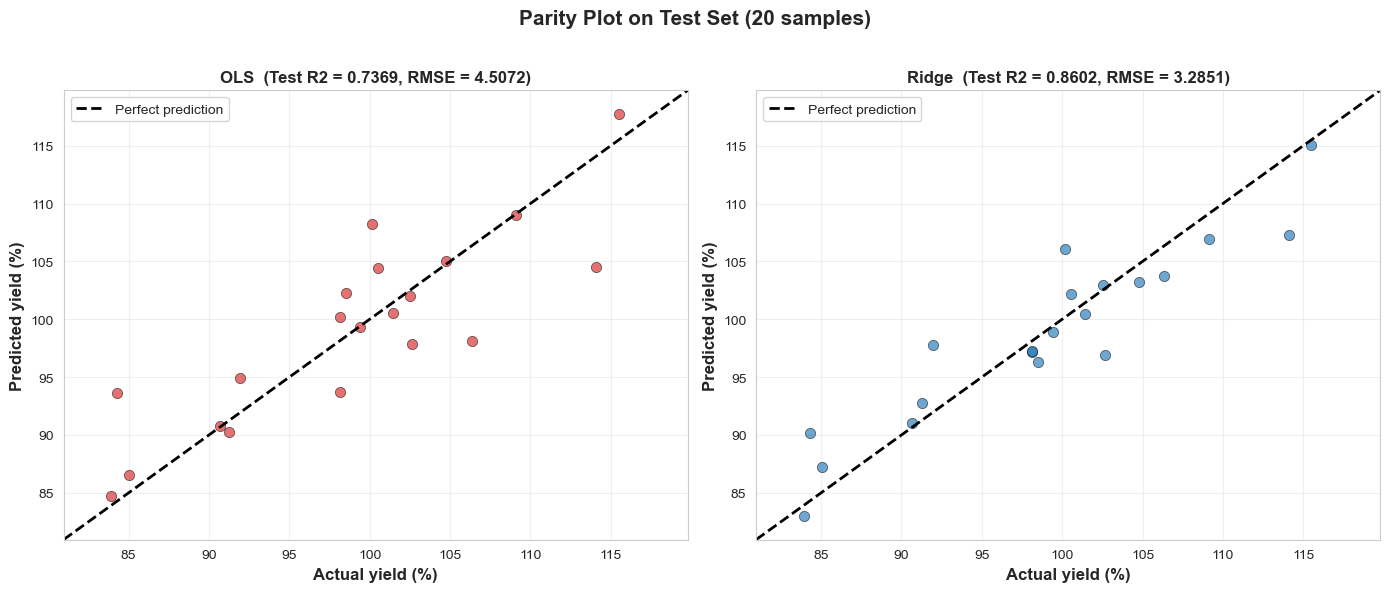

Ridge 的點更貼近對角線，尤其在極端產率（高/低）區間誤差更小。


In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

pred_ols = ols_model.predict(X_test_scaled)
pred_ridge = ridge_model.predict(X_test_scaled)
lo = min(y_test.min(), pred_ols.min(), pred_ridge.min()) - 2
hi = max(y_test.max(), pred_ols.max(), pred_ridge.max()) + 2

for ax, pred, name, color in [
    (axes[0], pred_ols, 'OLS', '#d62728'),
    (axes[1], pred_ridge, 'Ridge', '#1f77b4'),
]:
    ax.scatter(y_test, pred, alpha=0.65, s=55, color=color, edgecolor='black', linewidth=0.5)
    ax.plot([lo, hi], [lo, hi], 'k--', linewidth=2, label='Perfect prediction')
    ax.set_xlim(lo, hi)
    ax.set_ylim(lo, hi)
    ax.set_xlabel('Actual yield (%)', fontsize=12, fontweight='bold')
    ax.set_ylabel('Predicted yield (%)', fontsize=12, fontweight='bold')
    ax.set_title(f'{name}  (Test R2 = {r2_score(y_test, pred):.4f}, '
                 f'RMSE = {np.sqrt(mean_squared_error(y_test, pred)):.4f})',
                 fontsize=12, fontweight='bold')
    ax.legend(fontsize=10)
    ax.grid(True, alpha=0.3)

plt.suptitle('Parity Plot on Test Set (20 samples)', fontsize=15, fontweight='bold')
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig(FIG_DIR / 'parity_plot.png', dpi=300, bbox_inches='tight')
plt.show()

print("Ridge 的點更貼近對角線，尤其在極端產率（高/低）區間誤差更小。")

### 14.2 殘差分析

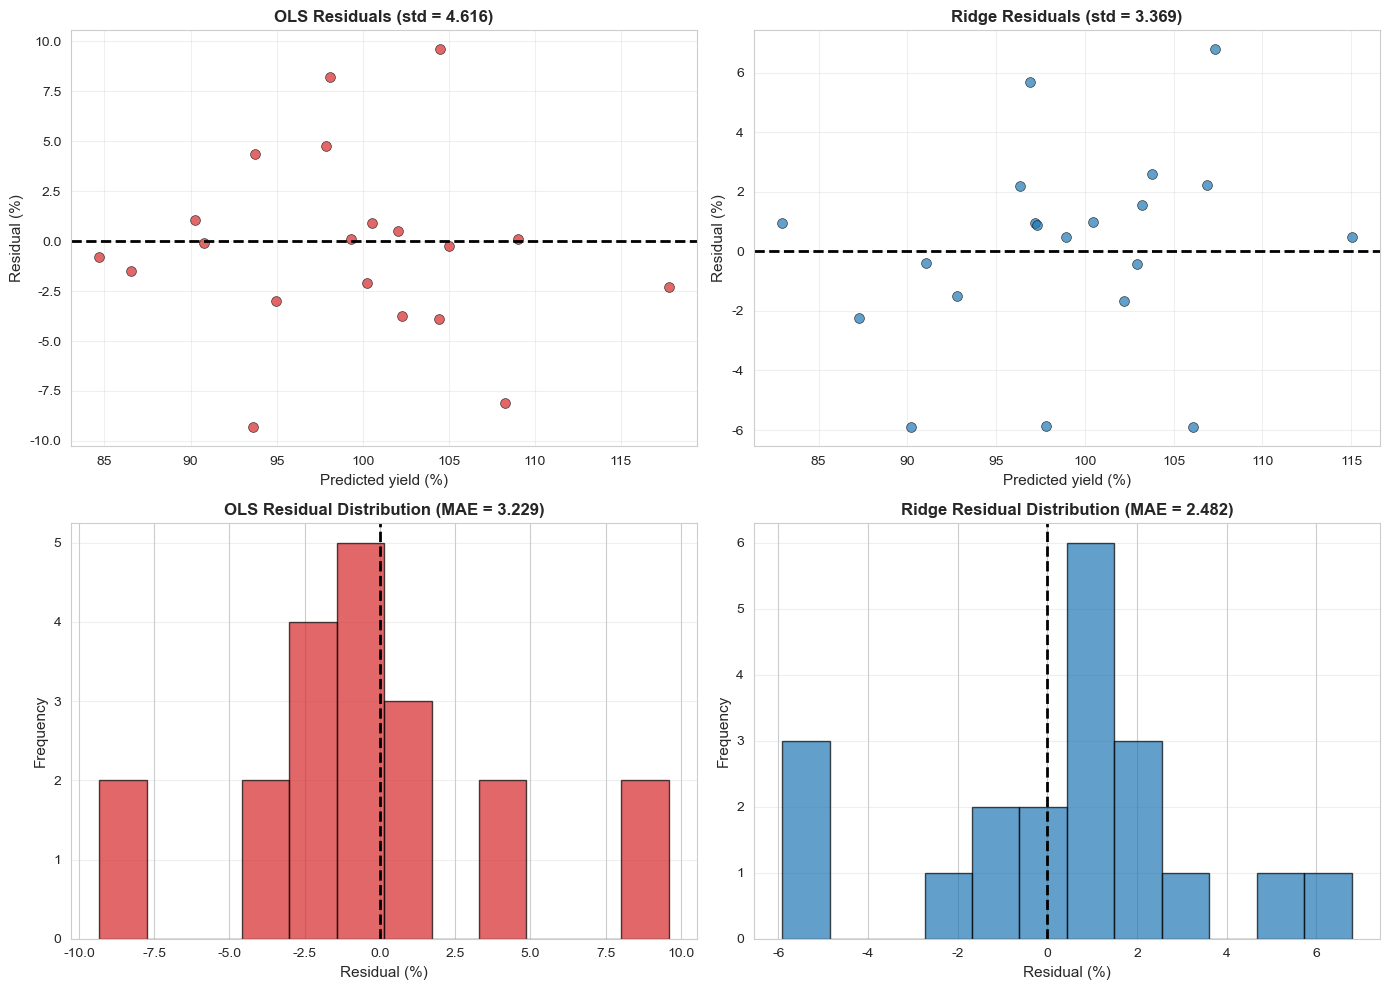

OLS   殘差標準差: 4.6159   MAE: 3.2293
Ridge 殘差標準差: 3.3692   MAE: 2.4819

Ridge 殘差分布更集中於 0，代表預測更可靠。


In [22]:
res_ols = y_test - pred_ols
res_ridge = y_test - pred_ridge

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

axes[0, 0].scatter(pred_ols, res_ols, alpha=0.7, s=50, color='#d62728',
                   edgecolor='black', linewidth=0.5)
axes[0, 0].axhline(y=0, color='black', linestyle='--', linewidth=2)
axes[0, 0].set_xlabel('Predicted yield (%)', fontsize=11)
axes[0, 0].set_ylabel('Residual (%)', fontsize=11)
axes[0, 0].set_title(f'OLS Residuals (std = {res_ols.std():.3f})', fontsize=12, fontweight='bold')
axes[0, 0].grid(True, alpha=0.3)

axes[0, 1].scatter(pred_ridge, res_ridge, alpha=0.7, s=50, color='#1f77b4',
                   edgecolor='black', linewidth=0.5)
axes[0, 1].axhline(y=0, color='black', linestyle='--', linewidth=2)
axes[0, 1].set_xlabel('Predicted yield (%)', fontsize=11)
axes[0, 1].set_ylabel('Residual (%)', fontsize=11)
axes[0, 1].set_title(f'Ridge Residuals (std = {res_ridge.std():.3f})', fontsize=12, fontweight='bold')
axes[0, 1].grid(True, alpha=0.3)

axes[1, 0].hist(res_ols, bins=12, color='#d62728', alpha=0.7, edgecolor='black')
axes[1, 0].axvline(x=0, color='black', linestyle='--', linewidth=2)
axes[1, 0].set_xlabel('Residual (%)', fontsize=11)
axes[1, 0].set_ylabel('Frequency', fontsize=11)
axes[1, 0].set_title(f'OLS Residual Distribution (MAE = {mean_absolute_error(y_test, pred_ols):.3f})',
                     fontsize=12, fontweight='bold')
axes[1, 0].grid(True, alpha=0.3, axis='y')

axes[1, 1].hist(res_ridge, bins=12, color='#1f77b4', alpha=0.7, edgecolor='black')
axes[1, 1].axvline(x=0, color='black', linestyle='--', linewidth=2)
axes[1, 1].set_xlabel('Residual (%)', fontsize=11)
axes[1, 1].set_ylabel('Frequency', fontsize=11)
axes[1, 1].set_title(f'Ridge Residual Distribution (MAE = {mean_absolute_error(y_test, pred_ridge):.3f})',
                     fontsize=12, fontweight='bold')
axes[1, 1].grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig(FIG_DIR / 'residual_analysis.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"OLS   殘差標準差: {res_ols.std():.4f}   MAE: {mean_absolute_error(y_test, pred_ols):.4f}")
print(f"Ridge 殘差標準差: {res_ridge.std():.4f}   MAE: {mean_absolute_error(y_test, pred_ridge):.4f}")
print(f"\nRidge 殘差分布更集中於 0，代表預測更可靠。")

---
## 15. 新操作條件預測：冗餘感測器讀數分歧的情境

在真實工廠中，同一物理量的多支感測器**很少完全一致**（校正漂移、局部位置差異、雜訊）。本節刻意讓冗餘感測器讀數出現分歧，模擬「儀表未同步校正」的現場狀況。

**這正是 OLS 最脆弱的場景**：它把同一份溫度資訊用三個互相抵消的大係數分配，一旦三支讀數不再吻合，這種補償關係立刻破裂，預測就跟著失控。

Ridge 因為係數被壓縮且方向一致，對讀數分歧的敏感度低得多。

新操作條件預測 vs 真實產率（真實模型不含雜訊）
Condition  True_Yield_%  OLS_Pred_%  Ridge_Pred_%  OLS_Error  Ridge_Error
       C1        83.150      75.867        83.286     -7.283        0.136
       C2       102.500     109.852       102.950      7.352        0.450
       C3       121.300     114.104       118.501     -7.196       -2.799

OLS   絕對誤差: [7.283 7.352 7.196]  (平均 7.277)
Ridge 絕對誤差: [0.136 0.45  2.799]  (平均 1.128)

Ridge 誤差為 OLS 的 0.16 倍（越小越好）
=> OLS 的誤差全部超過 7 個百分點，對產率控制而言完全不可接受。


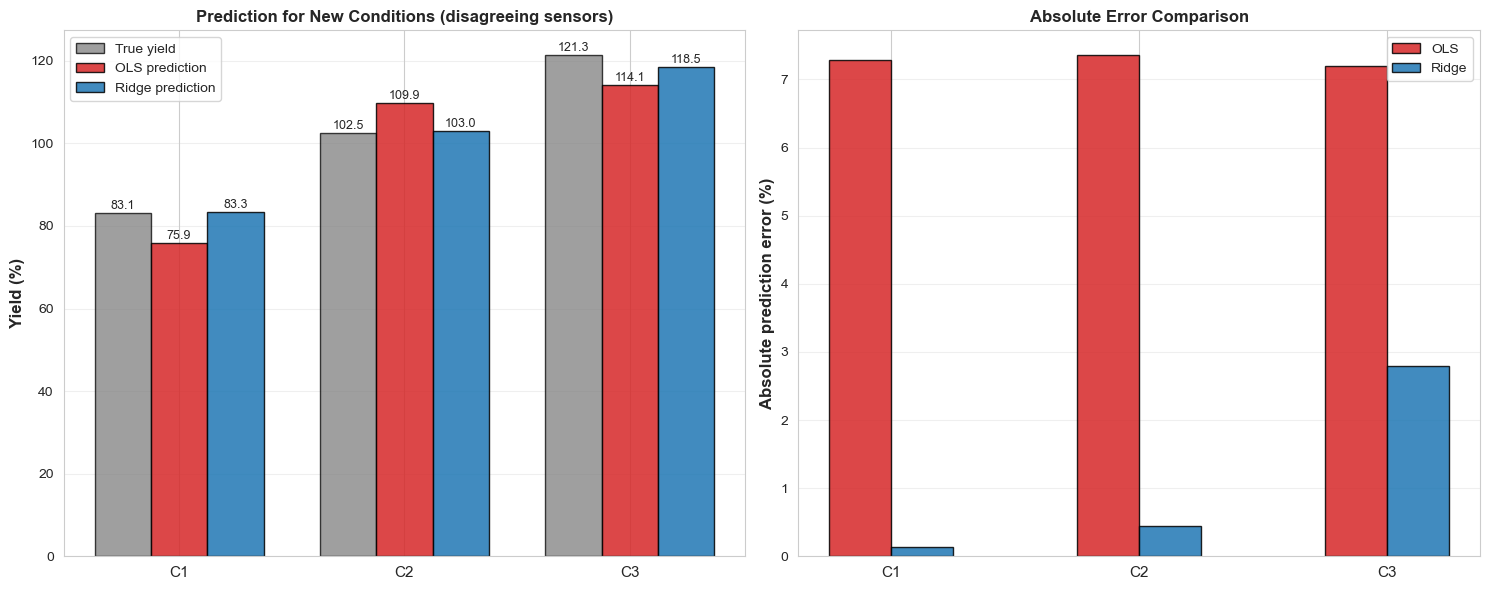


圖中可見 OLS 的預測誤差在所有條件下都遠大於 Ridge。
若把這個模型接上 APC 控制迴路，OLS 會給出錯誤的設定點建議。


In [23]:
new_conditions = pd.DataFrame({
    'T_TC1': [92.0, 105.0, 118.0],
    'T_TC2': [93.6, 103.2, 120.0],
    'T_TC3': [90.4, 106.8, 116.2],
    'P_PT1': [2.00, 3.20, 4.40],
    'P_PT2': [2.30, 2.90, 4.75],
    'C_AT1': [0.80, 1.50, 2.20],
    'C_AT2': [0.55, 1.80, 1.95],
    'Residence_min': [45.0, 110.0, 165.0],
    'Stirring_rpm': [280.0, 420.0, 560.0],
    'Feed_rate': [7.0, 10.0, 13.5],
    'Coolant_C': [60 - 0.8 * 92.0, 60 - 0.8 * 105.0, 60 - 0.8 * 118.0],
    'Ambient_RH': [45.0, 55.0, 65.0],
})

new_scaled = scaler.transform(new_conditions)

pred_new_ols = ols_model.predict(new_scaled)
pred_new_ridge = ridge_model.predict(new_scaled)

# 真實產率（不含雜訊），以 T_TC1 作為名目溫度
true_new = (20.0
            + 0.5 * new_conditions['T_TC1'].values
            + 3.0 * new_conditions['P_PT1'].values
            + 5.0 * new_conditions['C_AT1'].values
            + 0.05 * new_conditions['Residence_min'].values
            + 0.02 * new_conditions['Stirring_rpm'].values
            - 0.1 * new_conditions['Feed_rate'].values)

result_new = pd.DataFrame({
    'Condition': ['C1', 'C2', 'C3'],
    'True_Yield_%': true_new,
    'OLS_Pred_%': pred_new_ols,
    'Ridge_Pred_%': pred_new_ridge,
})
result_new['OLS_Error'] = result_new['OLS_Pred_%'] - result_new['True_Yield_%']
result_new['Ridge_Error'] = result_new['Ridge_Pred_%'] - result_new['True_Yield_%']

print("="*88)
print("新操作條件預測 vs 真實產率（真實模型不含雜訊）")
print("="*88)
print(result_new.to_string(index=False, float_format=lambda v: f'{v:9.3f}'))
print("="*88)

ols_mae_new = np.abs(result_new['OLS_Error']).mean()
ridge_mae_new = np.abs(result_new['Ridge_Error']).mean()
print(f"\nOLS   絕對誤差: {np.round(np.abs(result_new['OLS_Error'].values), 3)}"
      f"  (平均 {ols_mae_new:.3f})")
print(f"Ridge 絕對誤差: {np.round(np.abs(result_new['Ridge_Error'].values), 3)}"
      f"  (平均 {ridge_mae_new:.3f})")
print(f"\nRidge 誤差為 OLS 的 {ridge_mae_new / ols_mae_new:.2f} 倍（越小越好）")
print("=> OLS 的誤差全部超過 7 個百分點，對產率控制而言完全不可接受。")

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# 左：預測值 vs 真值
xp = np.arange(3)
w = 0.25
axes[0].bar(xp - w, result_new['True_Yield_%'], w, label='True yield',
            color='#7f7f7f', alpha=0.75, edgecolor='black')
axes[0].bar(xp, result_new['OLS_Pred_%'], w, label='OLS prediction',
            color='#d62728', alpha=0.85, edgecolor='black')
axes[0].bar(xp + w, result_new['Ridge_Pred_%'], w, label='Ridge prediction',
            color='#1f77b4', alpha=0.85, edgecolor='black')
axes[0].set_xticks(xp)
axes[0].set_xticklabels(['C1', 'C2', 'C3'], fontsize=11)
axes[0].set_ylabel('Yield (%)', fontsize=12, fontweight='bold')
axes[0].set_title('Prediction for New Conditions (disagreeing sensors)',
                  fontsize=12, fontweight='bold')
axes[0].legend(fontsize=10)
axes[0].grid(True, alpha=0.3, axis='y')
for i in range(3):
    axes[0].text(i - w, result_new['True_Yield_%'].iloc[i] + 1,
                 f"{result_new['True_Yield_%'].iloc[i]:.1f}", ha='center', fontsize=9)
    axes[0].text(i, result_new['OLS_Pred_%'].iloc[i] + 1,
                 f"{result_new['OLS_Pred_%'].iloc[i]:.1f}", ha='center', fontsize=9)
    axes[0].text(i + w, result_new['Ridge_Pred_%'].iloc[i] + 1,
                 f"{result_new['Ridge_Pred_%'].iloc[i]:.1f}", ha='center', fontsize=9)

# 右：絕對誤差
axes[1].bar(xp - w/2, np.abs(result_new['OLS_Error']), w,
            label='OLS', color='#d62728', alpha=0.85, edgecolor='black')
axes[1].bar(xp + w/2, np.abs(result_new['Ridge_Error']), w,
            label='Ridge', color='#1f77b4', alpha=0.85, edgecolor='black')
axes[1].set_xticks(xp)
axes[1].set_xticklabels(['C1', 'C2', 'C3'], fontsize=11)
axes[1].set_ylabel('Absolute prediction error (%)', fontsize=12, fontweight='bold')
axes[1].set_title('Absolute Error Comparison', fontsize=12, fontweight='bold')
axes[1].legend(fontsize=10)
axes[1].grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig(FIG_DIR / 'new_predictions.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n圖中可見 OLS 的預測誤差在所有條件下都遠大於 Ridge。")
print("若把這個模型接上 APC 控制迴路，OLS 會給出錯誤的設定點建議。")

---
## 16. 模型持久化

Ridge 模型與 Scaler 必須**成對儲存**。預測新資料時，務必使用同一組標準化參數，否則結果會完全錯誤。

In [24]:
model_path = MODEL_DIR / 'ridge_model.pkl'
scaler_path = MODEL_DIR / 'scaler.pkl'
joblib.dump(ridge_model, model_path)
joblib.dump(scaler, scaler_path)

print(f"✓ Ridge 模型已儲存: {model_path}")
print(f"✓ Scaler 已儲存: {scaler_path}")

model_info = {
    'model_type': 'Ridge Regression (v2: small-sample collinearity demo)',
    'best_alpha': float(best_alpha),
    'n_samples': int(N_SAMPLES),
    'n_features': int(X.shape[1]),
    'features': list(X.columns),
    'intercept': float(ridge_model.intercept_),
    'coefficients': {k: float(v) for k, v in zip(X.columns, ridge_model.coef_)},
    'ols_coefficients': {k: float(v) for k, v in zip(X.columns, ols_model.coef_)},
    'ridge_test_r2': float(ridge_test_r2),
    'ols_test_r2': float(ols_test_r2),
    'ridge_test_rmse': float(ridge_test_rmse),
    'ols_test_rmse': float(ols_test_rmse),
    'cv_ridge_mean_r2': float(cv_ridge.mean()),
    'cv_ols_mean_r2': float(cv_ols.mean()),
    'bootstrap_ols_std_mean': float(boot_df['OLS_std'].mean()),
    'bootstrap_ridge_std_mean': float(boot_df['Ridge_std'].mean()),
}

info_path = MODEL_DIR / 'model_info.json'
with open(info_path, 'w', encoding='utf-8') as f:
    json.dump(model_info, f, indent=4, ensure_ascii=False)
print(f"✓ 模型資訊已儲存: {info_path}")

# 載入驗證
loaded_model = joblib.load(model_path)
loaded_scaler = joblib.load(scaler_path)
reload_pred = loaded_model.predict(loaded_scaler.transform(new_conditions))
print(f"\n✓ 載入驗證（與原預測一致）: {np.round(reload_pred, 4)}")
print(f"  原預測值                : {np.round(pred_new_ridge, 4)}")
print(f"  最大差異: {np.abs(reload_pred - pred_new_ridge).max():.2e}")

✓ Ridge 模型已儲存: d:\MyGit\ChemE-3590\Part_3\Unit10\outputs\P3_Unit10_Ridge_Regression_v2\models\ridge_model.pkl
✓ Scaler 已儲存: d:\MyGit\ChemE-3590\Part_3\Unit10\outputs\P3_Unit10_Ridge_Regression_v2\models\scaler.pkl
✓ 模型資訊已儲存: d:\MyGit\ChemE-3590\Part_3\Unit10\outputs\P3_Unit10_Ridge_Regression_v2\models\model_info.json

✓ 載入驗證（與原預測一致）: [ 83.2855 102.9505 118.5014]
  原預測值                : [ 83.2855 102.9505 118.5014]
  最大差異: 0.00e+00


---
## 17. 總結

本 Notebook 用一個刻意設計的極端案例，把 Ridge 的價值具體化。

In [25]:
print("="*78)
print("Unit10 Ridge Regression (v2) 實驗總結")
print("="*78)

print("\n【問題設定】")
print(f"  樣本數 n = {N_SAMPLES} (訓練集 {X_train.shape[0]} 筆)")
print(f"  特徵數 p = {X.shape[1]}")
print(f"  訓練集 n/p = {X_train.shape[0] / X_train.shape[1]:.2f}")
print(f"  最大 VIF = {vif_data['VIF'].iloc[0]:.1f} ({vif_data['Feature'].iloc[0]})")
print(f"  VIF > 100 的特徵: {n_extreme} 個")

print("\n【係數穩定性】")
print(f"  OLS   最大 |coef| = {ols_max:.1f}")
print(f"  Ridge 最大 |coef| = {ridge_max:.1f}   (縮小 {ols_max / ridge_max:.1f} 倍)")
print(f"  Bootstrap 平均標準差: OLS {boot_df['OLS_std'].mean():.2f} vs Ridge {boot_df['Ridge_std'].mean():.2f}")
print(f"  穩定度改善: {boot_df['Ratio_OLS_over_Ridge'].mean():.1f}x")

print("\n【泛化能力（單次切分）】")
print(f"  OLS   Test R2 = {ols_test_r2:.4f}, RMSE = {ols_test_rmse:.4f}")
print(f"  Ridge Test R2 = {ridge_test_r2:.4f}, RMSE = {ridge_test_rmse:.4f}")
print(f"  R2 提升 {ridge_test_r2 - ols_test_r2:+.4f}，RMSE 降低 {ols_test_rmse - ridge_test_rmse:.4f}")

print("\n【泛化能力（20 次隨機切分）】")
print(f"  Ridge 勝出 {ridge_wins}/{N_SPLITS} 次")
print(f"  平均 R2 提升 {split_df['R2_gain'].mean():+.4f}")
print(f"  平均 RMSE 降幅 {split_df['RMSE_reduction_pct'].mean():.1f}%")

print("\n【交叉驗證】")
print(f"  OLS   CV R2 = {cv_ols.mean():.4f} +/- {cv_ols.std():.4f}")
print(f"  Ridge CV R2 = {cv_ridge.mean():.4f} +/- {cv_ridge.std():.4f}")

print("\n【適用邊界】")
print(f"  n <= 50 時，Ridge 平均 R2 提升 {small['R2_gain'].mean():+.4f}")
print(f"  n >= 300 時，Ridge 平均 R2 提升 {large['R2_gain'].mean():+.4f}（優勢消失）")

print("\n" + "="*78)
print("【核心結論】")
print("="*78)
print("1. Ridge 的價值不在於『一定比 OLS 準』，而在於『OLS 失效時提供唯一可行解』")
print("2. 判準: VIF > 10 且 n/p < 5 時，務必改用 Ridge")
print("3. Ridge 保留全部特徵，係數收縮但方向正確，適合需要物理解釋的場合")
print("4. 樣本充足 (n/p > 20) 時，OLS 已足夠，Ridge 反而引入不必要偏差")
print("5. 原範例 (n=500, p=4, VIF~1.6) 的設定本來就讓 Ridge 無用武之地")

print("\n【下一步建議】")
print("  1. 若需特徵選擇（去掉冗餘感測器），改用 Lasso 或 Elastic Net")
print("  2. 用 PCA 先消除共線性再回歸（PCR）")
print("  3. 以領域知識合併冗餘訊號（3 支熱電偶取平均）從根本解決共線性")
print("  4. 樣本累積後重新評估，alpha 應隨資料量增大而下修")
print("="*78)
print("\n✓ Unit10 Ridge Regression v2 完成！")

Unit10 Ridge Regression (v2) 實驗總結

【問題設定】
  樣本數 n = 50 (訓練集 30 筆)
  特徵數 p = 12
  訓練集 n/p = 2.50
  最大 VIF = 1163.4 (T_TC3)
  VIF > 100 的特徵: 7 個

【係數穩定性】
  OLS   最大 |coef| = 45.5
  Ridge 最大 |coef| = 3.0   (縮小 15.3 倍)
  Bootstrap 平均標準差: OLS 25.58 vs Ridge 0.84
  穩定度改善: 34.2x

【泛化能力（單次切分）】
  OLS   Test R2 = 0.7369, RMSE = 4.5072
  Ridge Test R2 = 0.8602, RMSE = 3.2851
  R2 提升 +0.1234，RMSE 降低 1.2221

【泛化能力（20 次隨機切分）】
  Ridge 勝出 16/20 次
  平均 R2 提升 +0.0229
  平均 RMSE 降幅 5.4%

【交叉驗證】
  OLS   CV R2 = 0.5975 +/- 0.2122
  Ridge CV R2 = 0.6794 +/- 0.0819

【適用邊界】
  n <= 50 時，Ridge 平均 R2 提升 +1.1681
  n >= 300 時，Ridge 平均 R2 提升 -0.0009（優勢消失）

【核心結論】
1. Ridge 的價值不在於『一定比 OLS 準』，而在於『OLS 失效時提供唯一可行解』
2. 判準: VIF > 10 且 n/p < 5 時，務必改用 Ridge
3. Ridge 保留全部特徵，係數收縮但方向正確，適合需要物理解釋的場合
4. 樣本充足 (n/p > 20) 時，OLS 已足夠，Ridge 反而引入不必要偏差
5. 原範例 (n=500, p=4, VIF~1.6) 的設定本來就讓 Ridge 無用武之地

【下一步建議】
  1. 若需特徵選擇（去掉冗餘感測器），改用 Lasso 或 Elastic Net
  2. 用 PCA 先消除共線性再回歸（PCR）
  3. 以領域知識合併冗餘訊號（3 支熱電偶取平均）從根本解決共線性
  4. 樣本累積後重新評估，alpha 應隨資料量

---

**課程資訊**
- 課程名稱：AI在化工上之應用 (ChemE 3590)
- 課程單元：Unit10 Ridge回歸 (v2 進階範例)
- 課程製作：逢甲大學 化工系 智慧程序系統工程實驗室
- 授課教師：莊曜禎 助理教授
- 更新日期：2026-11-20

**課程授權 [CC BY-NC-SA 4.0]**
 - 本教材遵循 [創用CC 姓名標示-非商業性-相同方式分享 4.0 國際 (CC BY-NC-SA 4.0)](https://creativecommons.org/licenses/by-nc-sa/4.0/deed.zh) 授權。